# Research Journal — Robustness Testing for LLM-Based Text-to-Cypher Systems
**Student:** Shreya Nair  
**Date Started:** 25 June 2026  
**Subject:** 41029 / 41030 Capstone Project

---

## Entry 1 — 25 June 2026 

### What I did today
- Set up VS Code development environment on MacBook Pro M2
- Created Python virtual environment (Python 3.13.2)
- Installed all required libraries: datasets, pandas, sacrebleu, 
  jupyter, notebook, matplotlib, scipy, google-generativeai, neo4j
- Obtained Gemini 1.5 Flash API key via Google AI Studio (free tier)
- Downloaded Neo4j Text2Cypher 2024v1 dataset from HuggingFace

### Dataset observations
- Total training rows: 39,554
- Total test rows: 4,833
- Columns: question, schema, cypher, data_source, 
  instance_id, database_reference_alias
- Sample questions span multiple domains: finance (fincen), 
  companies, gaming (twitch)
- Each row contains the natural language question, the graph 
  schema, and the reference Cypher query — exactly what is 
  needed for this project

### Scope note
My proposal specified GPT-4o via OpenAI API. Due to zero-cost 
constraint and 8GB RAM limitation on local machine, I am using 
Google Gemini 1.5 Flash (free tier, 1500 requests/day) instead. 
This is documented as a scope adjustment. The pipeline is 
model-agnostic and this change does not affect the research 
questions or methodology.

### What I need to do next
- Install Docker Desktop and set up Neo4j locally
- Explore the dataset further — understand query complexity levels
- Plan and implement stratified sampling of 200 questions
- Test Gemini API with a sample query

### Current status vs timeline
- Phase 1 (Setup): Complete as of today
- Phase 2 (Dataset & Query Generation): Starting now — on track

## Entry 2 — 30 June 2026
**Session duration:** 2 hours  
**Phase:** Phase 1 complete, Phase 2 begins  
**Goal:** Install Docker, run Neo4j, test Gemini API

---

### What I did and why

**Docker + Neo4j**  
I needed a real graph database running on my Mac so I can 
test whether AI-generated Cypher queries actually work. 
Docker is the tool that runs Neo4j safely in the background 
like a little box — nothing else on my Mac gets affected.

Installed Docker Desktop, pulled Neo4j 5.18, and started 
it running. Checked it worked by visiting localhost:7474 
in my browser and logging in successfully.

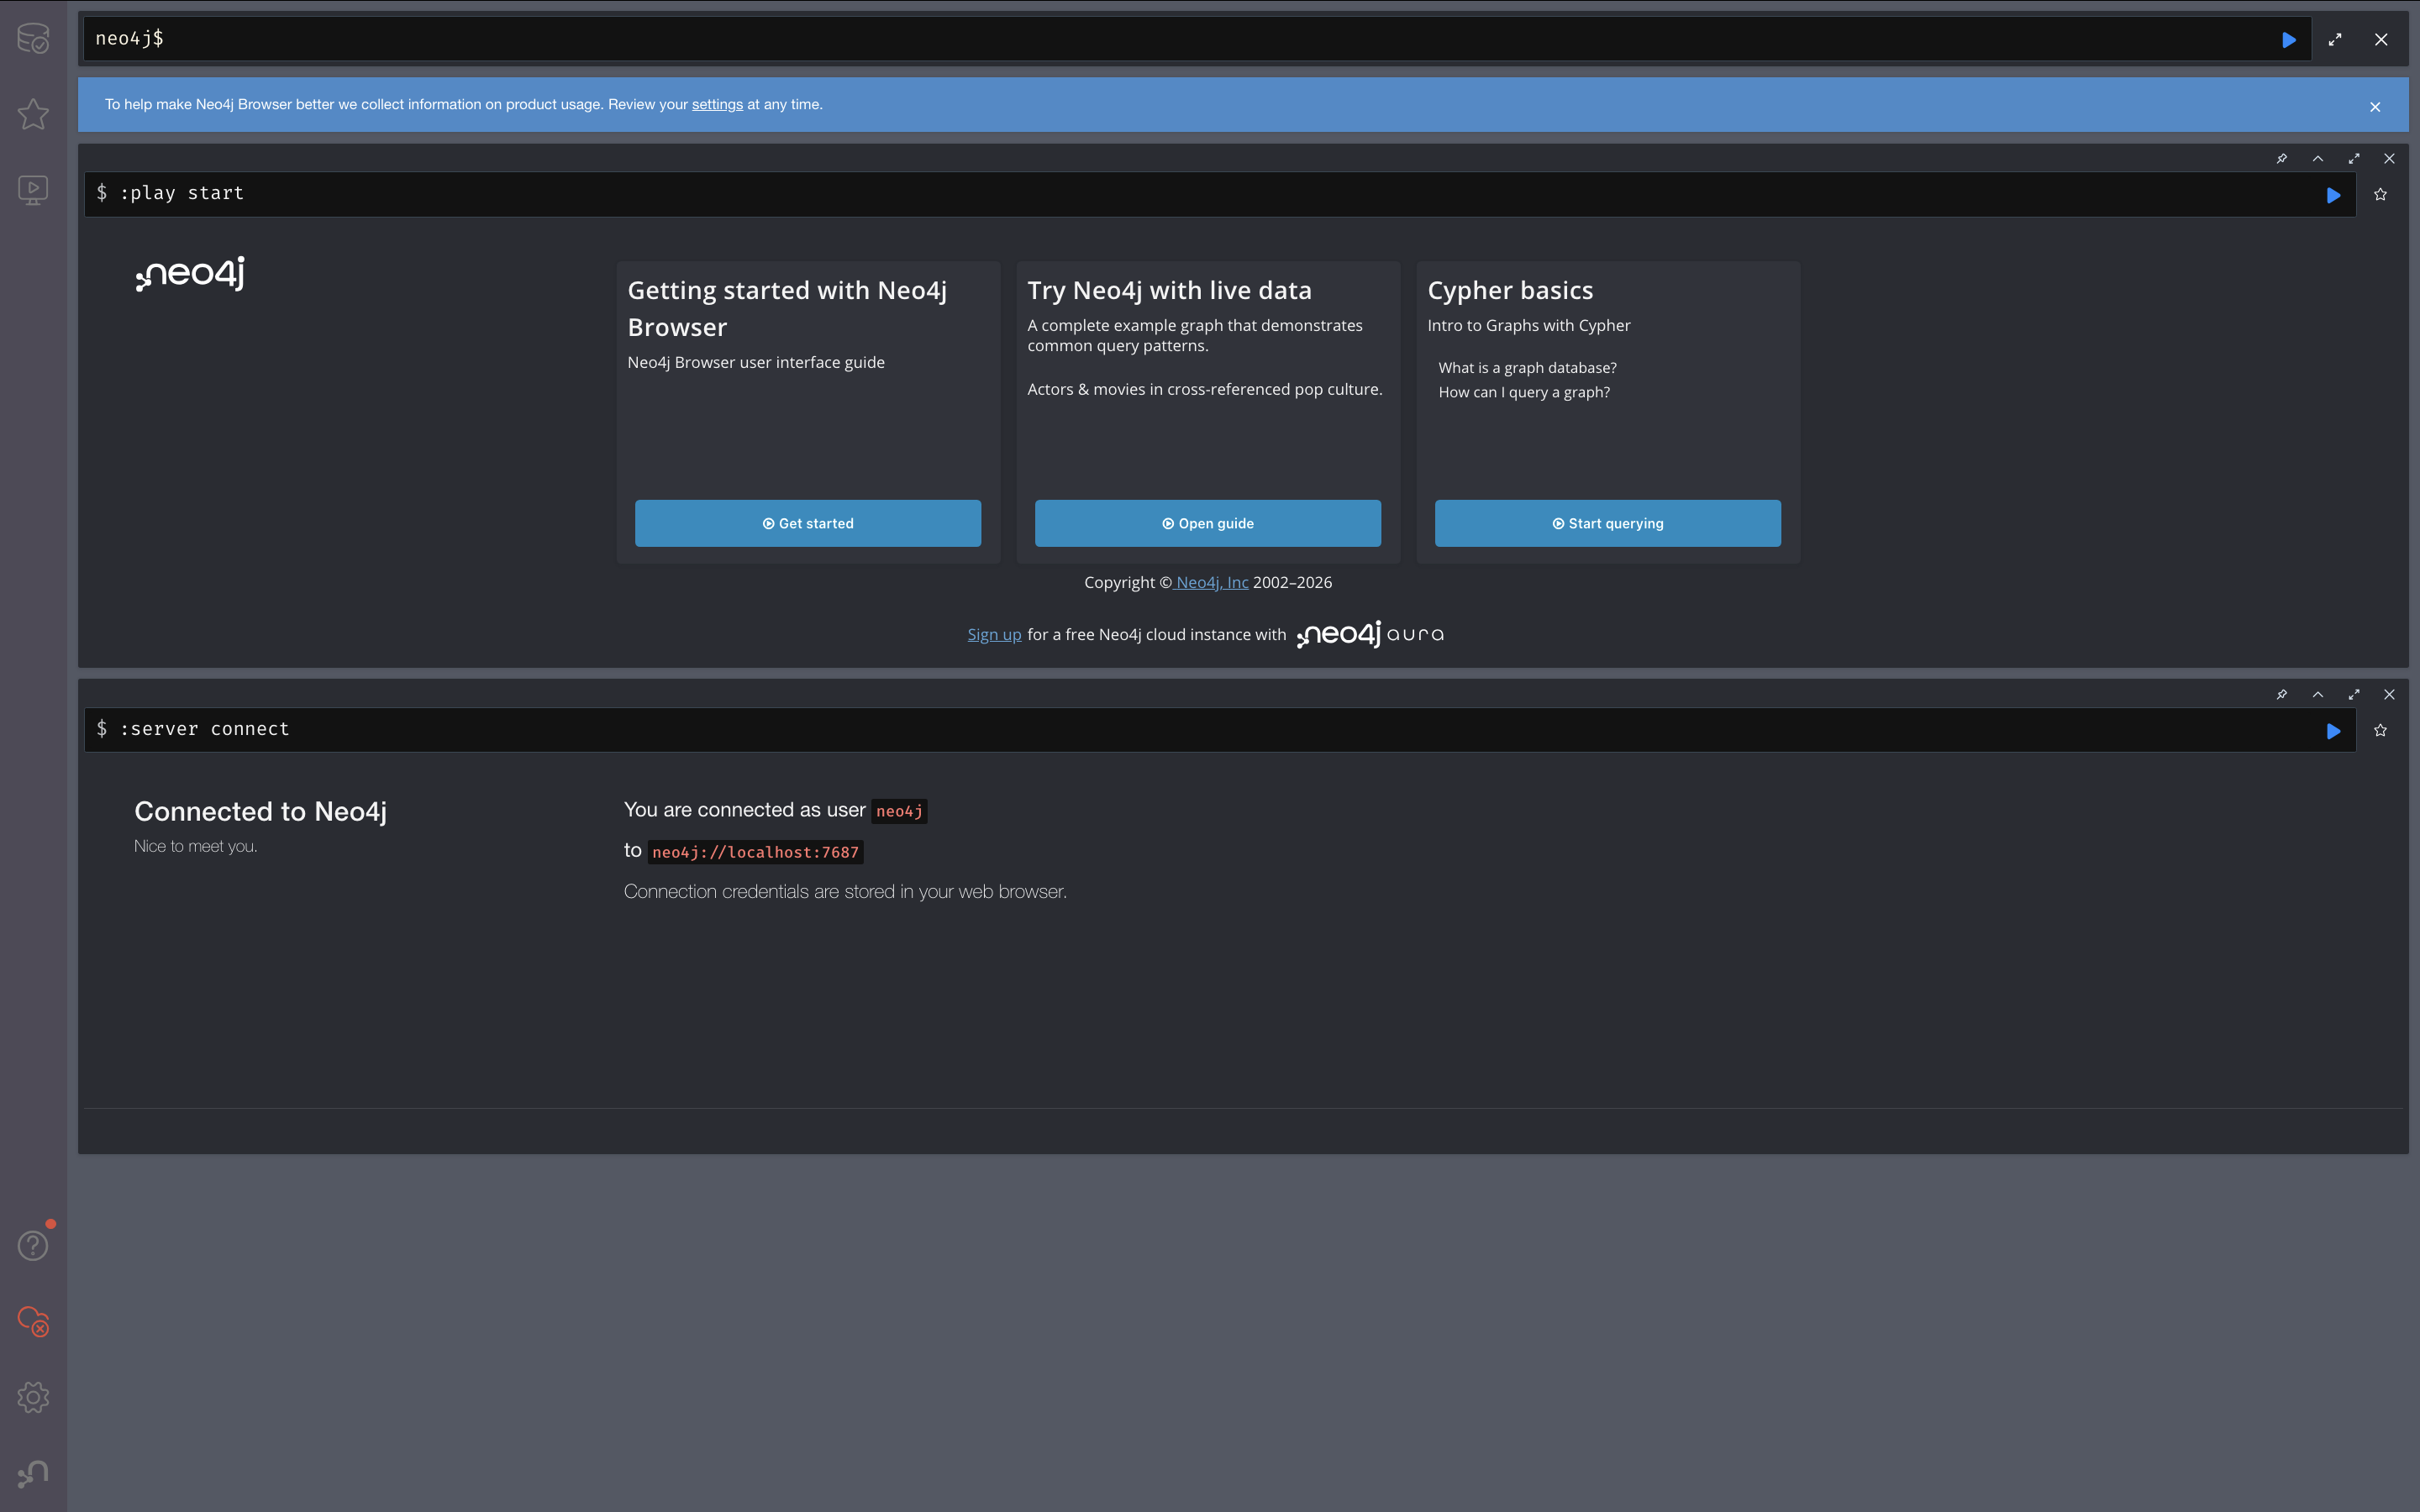

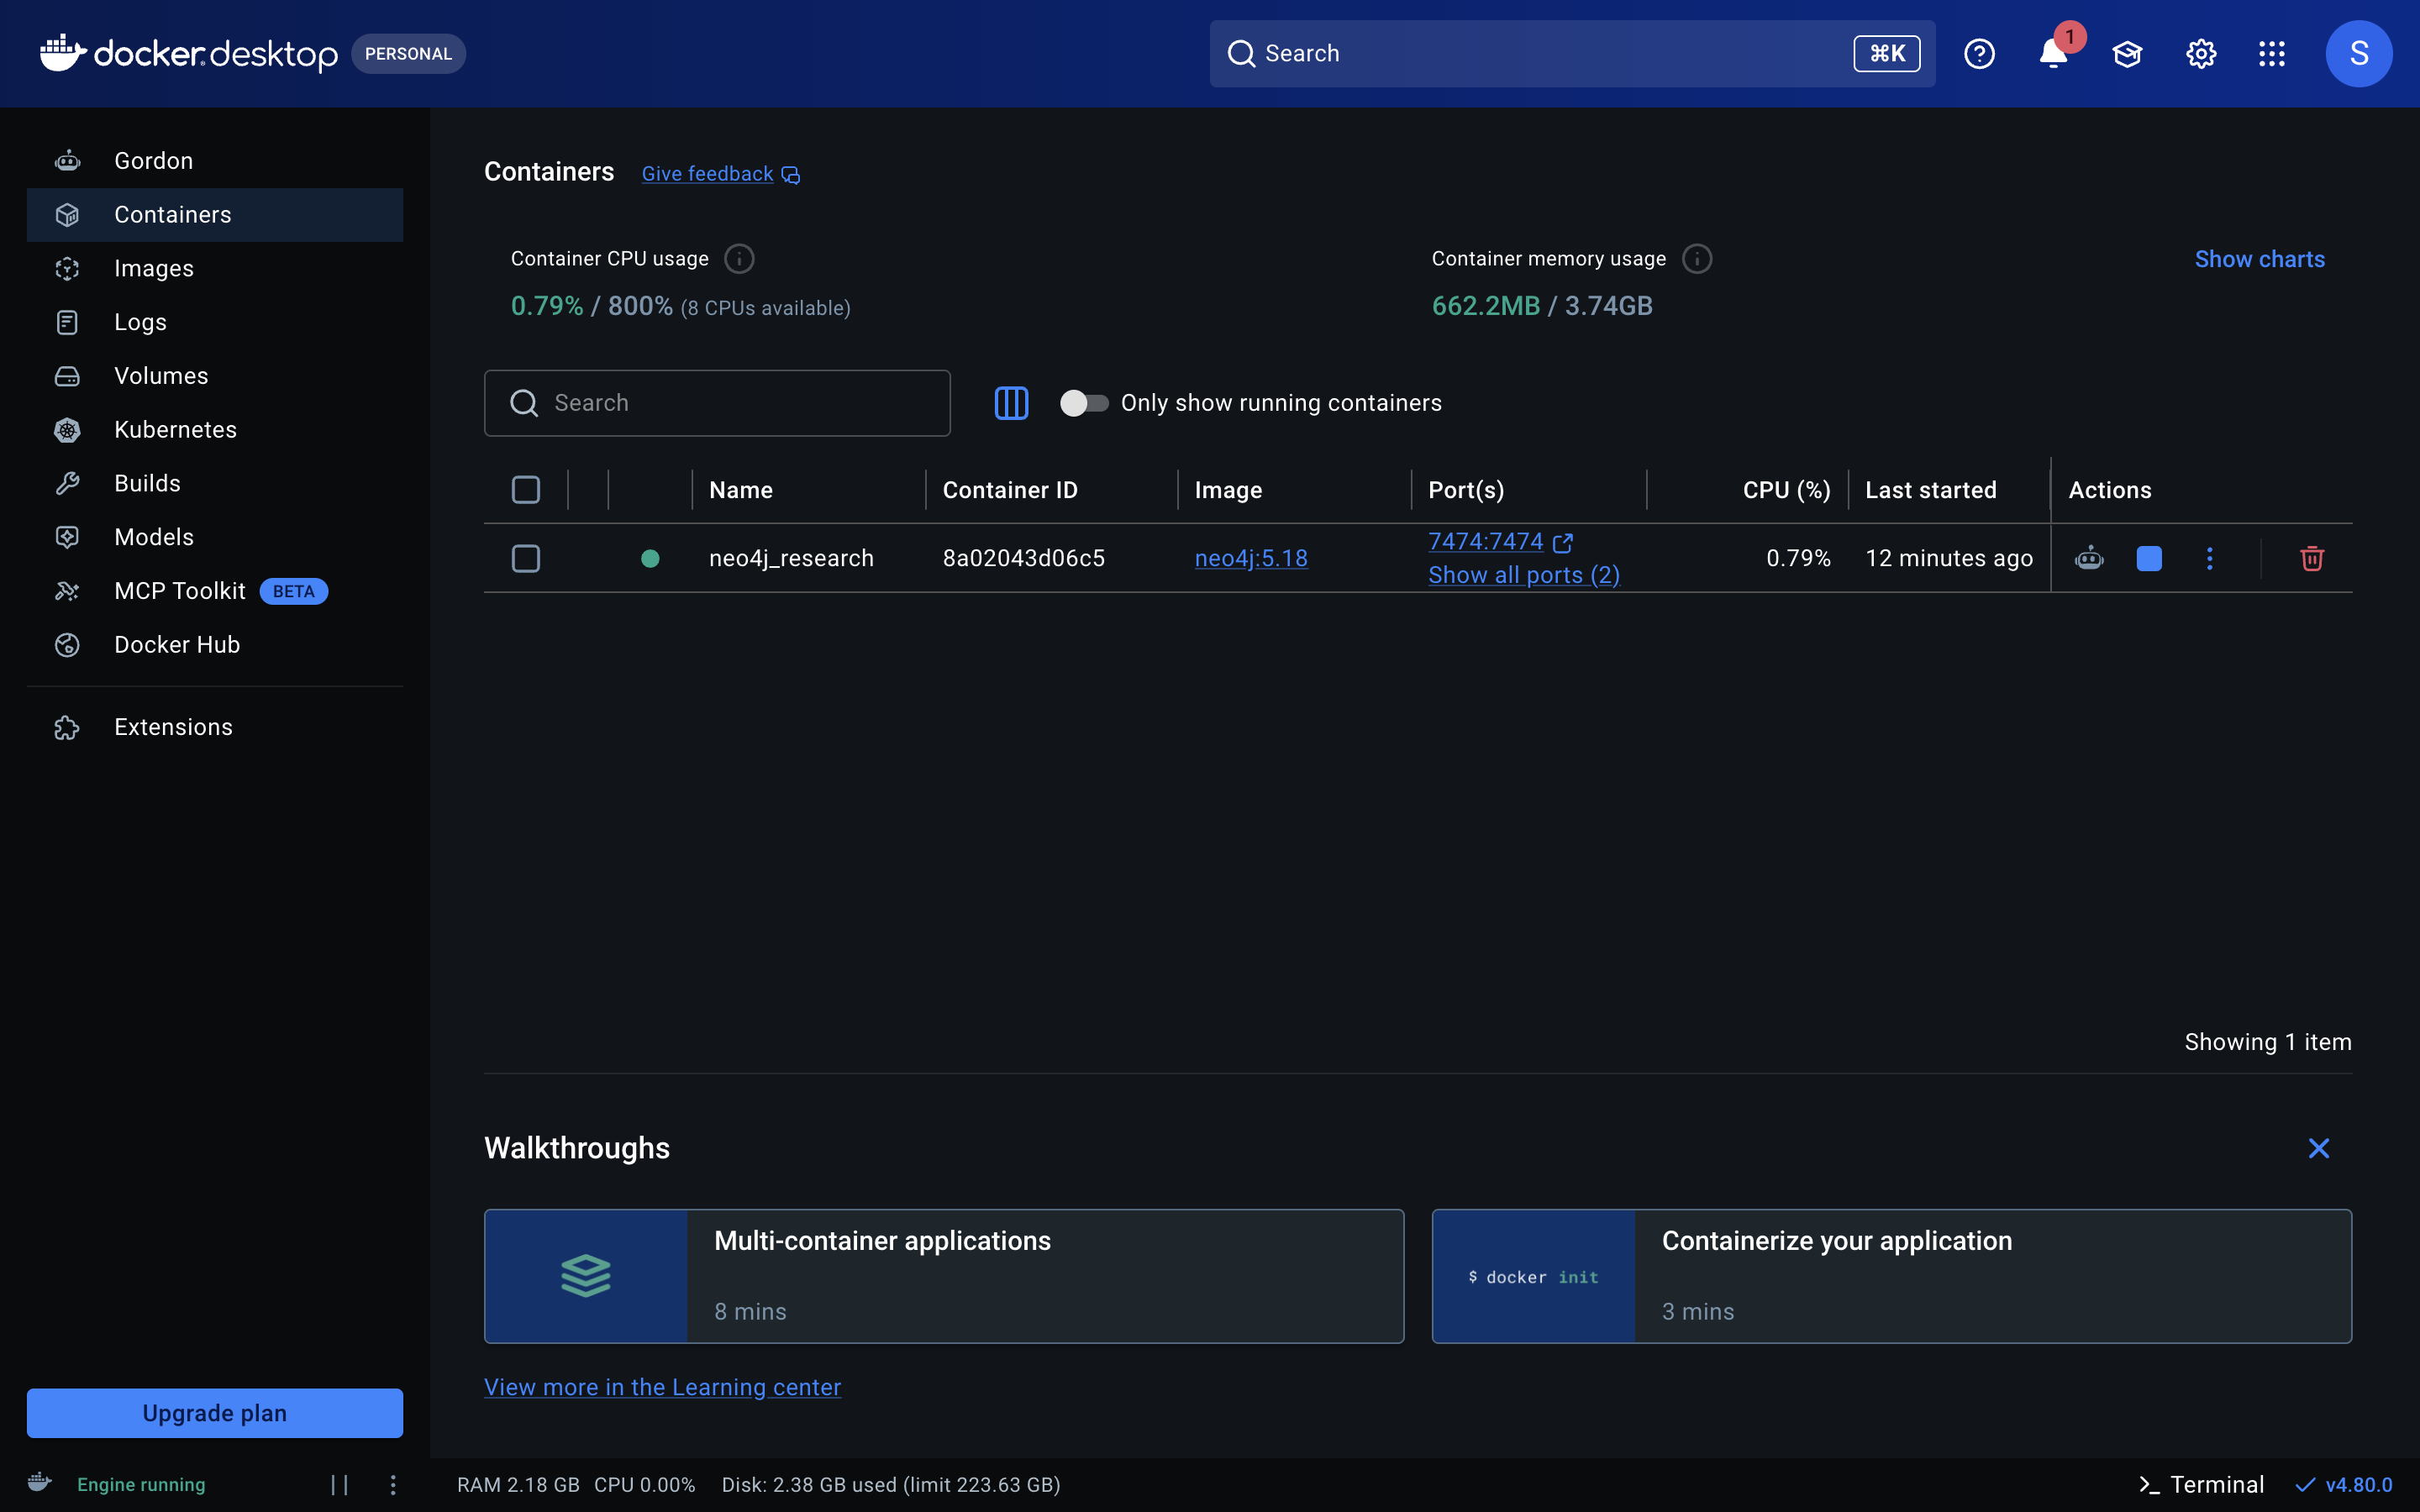

---

**Gemini API setup — errors and fixes**  
This took longer than expected. Here is exactly what went 
wrong and how I fixed it:

**Problem 1 — Wrong library**  
The library google.generativeai is now deprecated.  
Fix: Switched to google.genai

**Problem 2 — Model name wrong (404 error)**  
gemini-1.5-flash no longer exists.  
Fix: Ran list_models.py to see all available models.

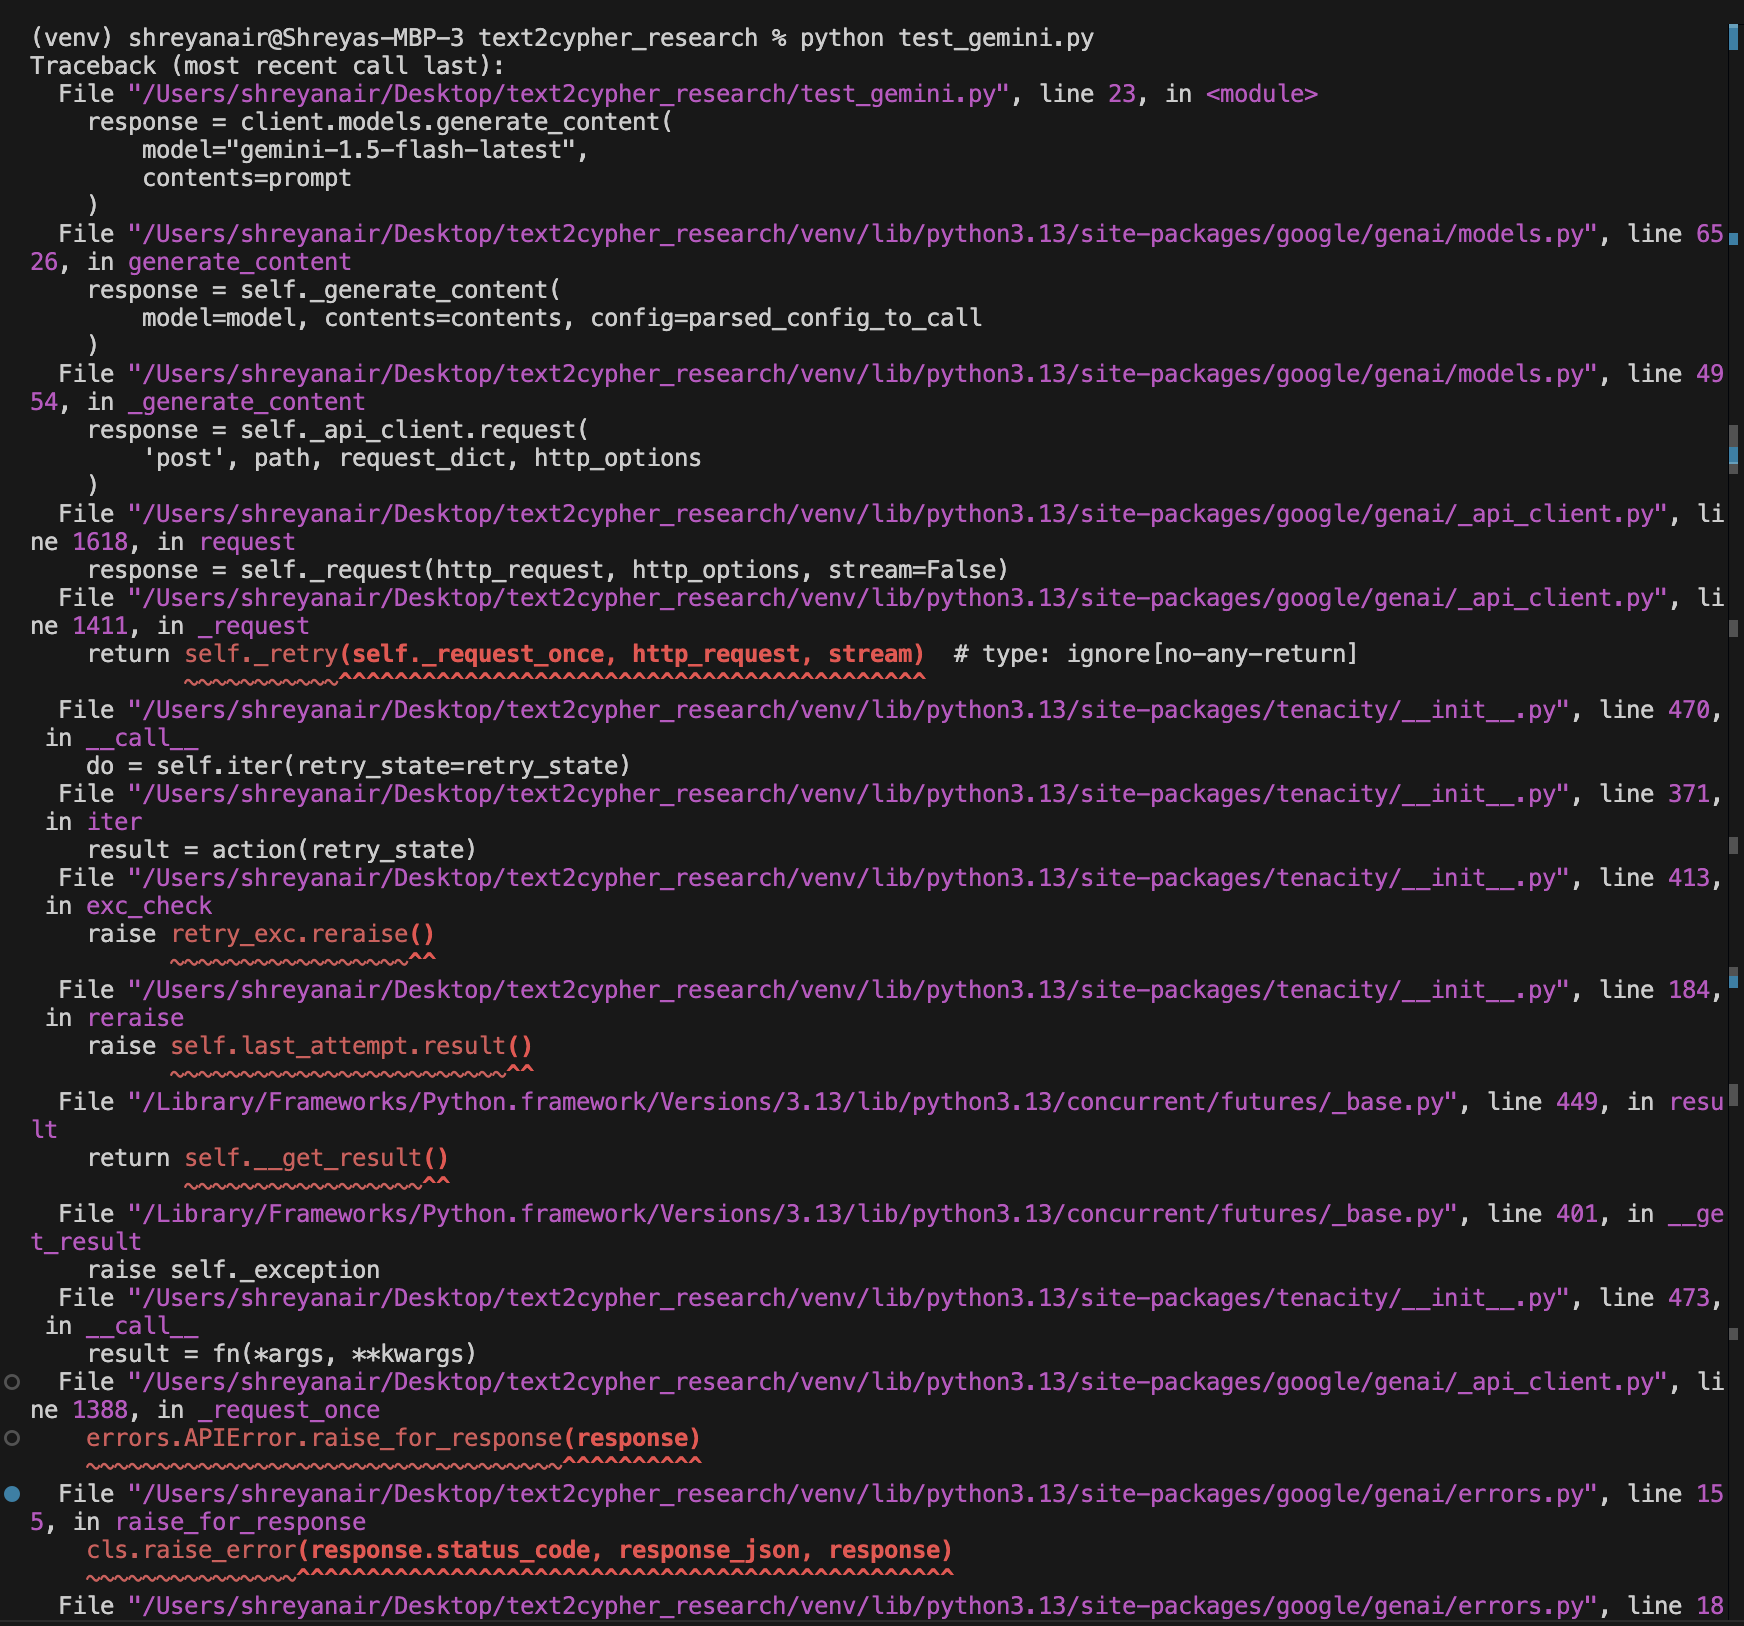

**Problem 3 — Quota showing zero (429 error)**  
gemini-2.0-flash had zero free tier allowance on my account.  
Fix: Checked rate limit page on Google AI Studio and found 
gemini-2.5-flash-lite has 10 requests per minute free.

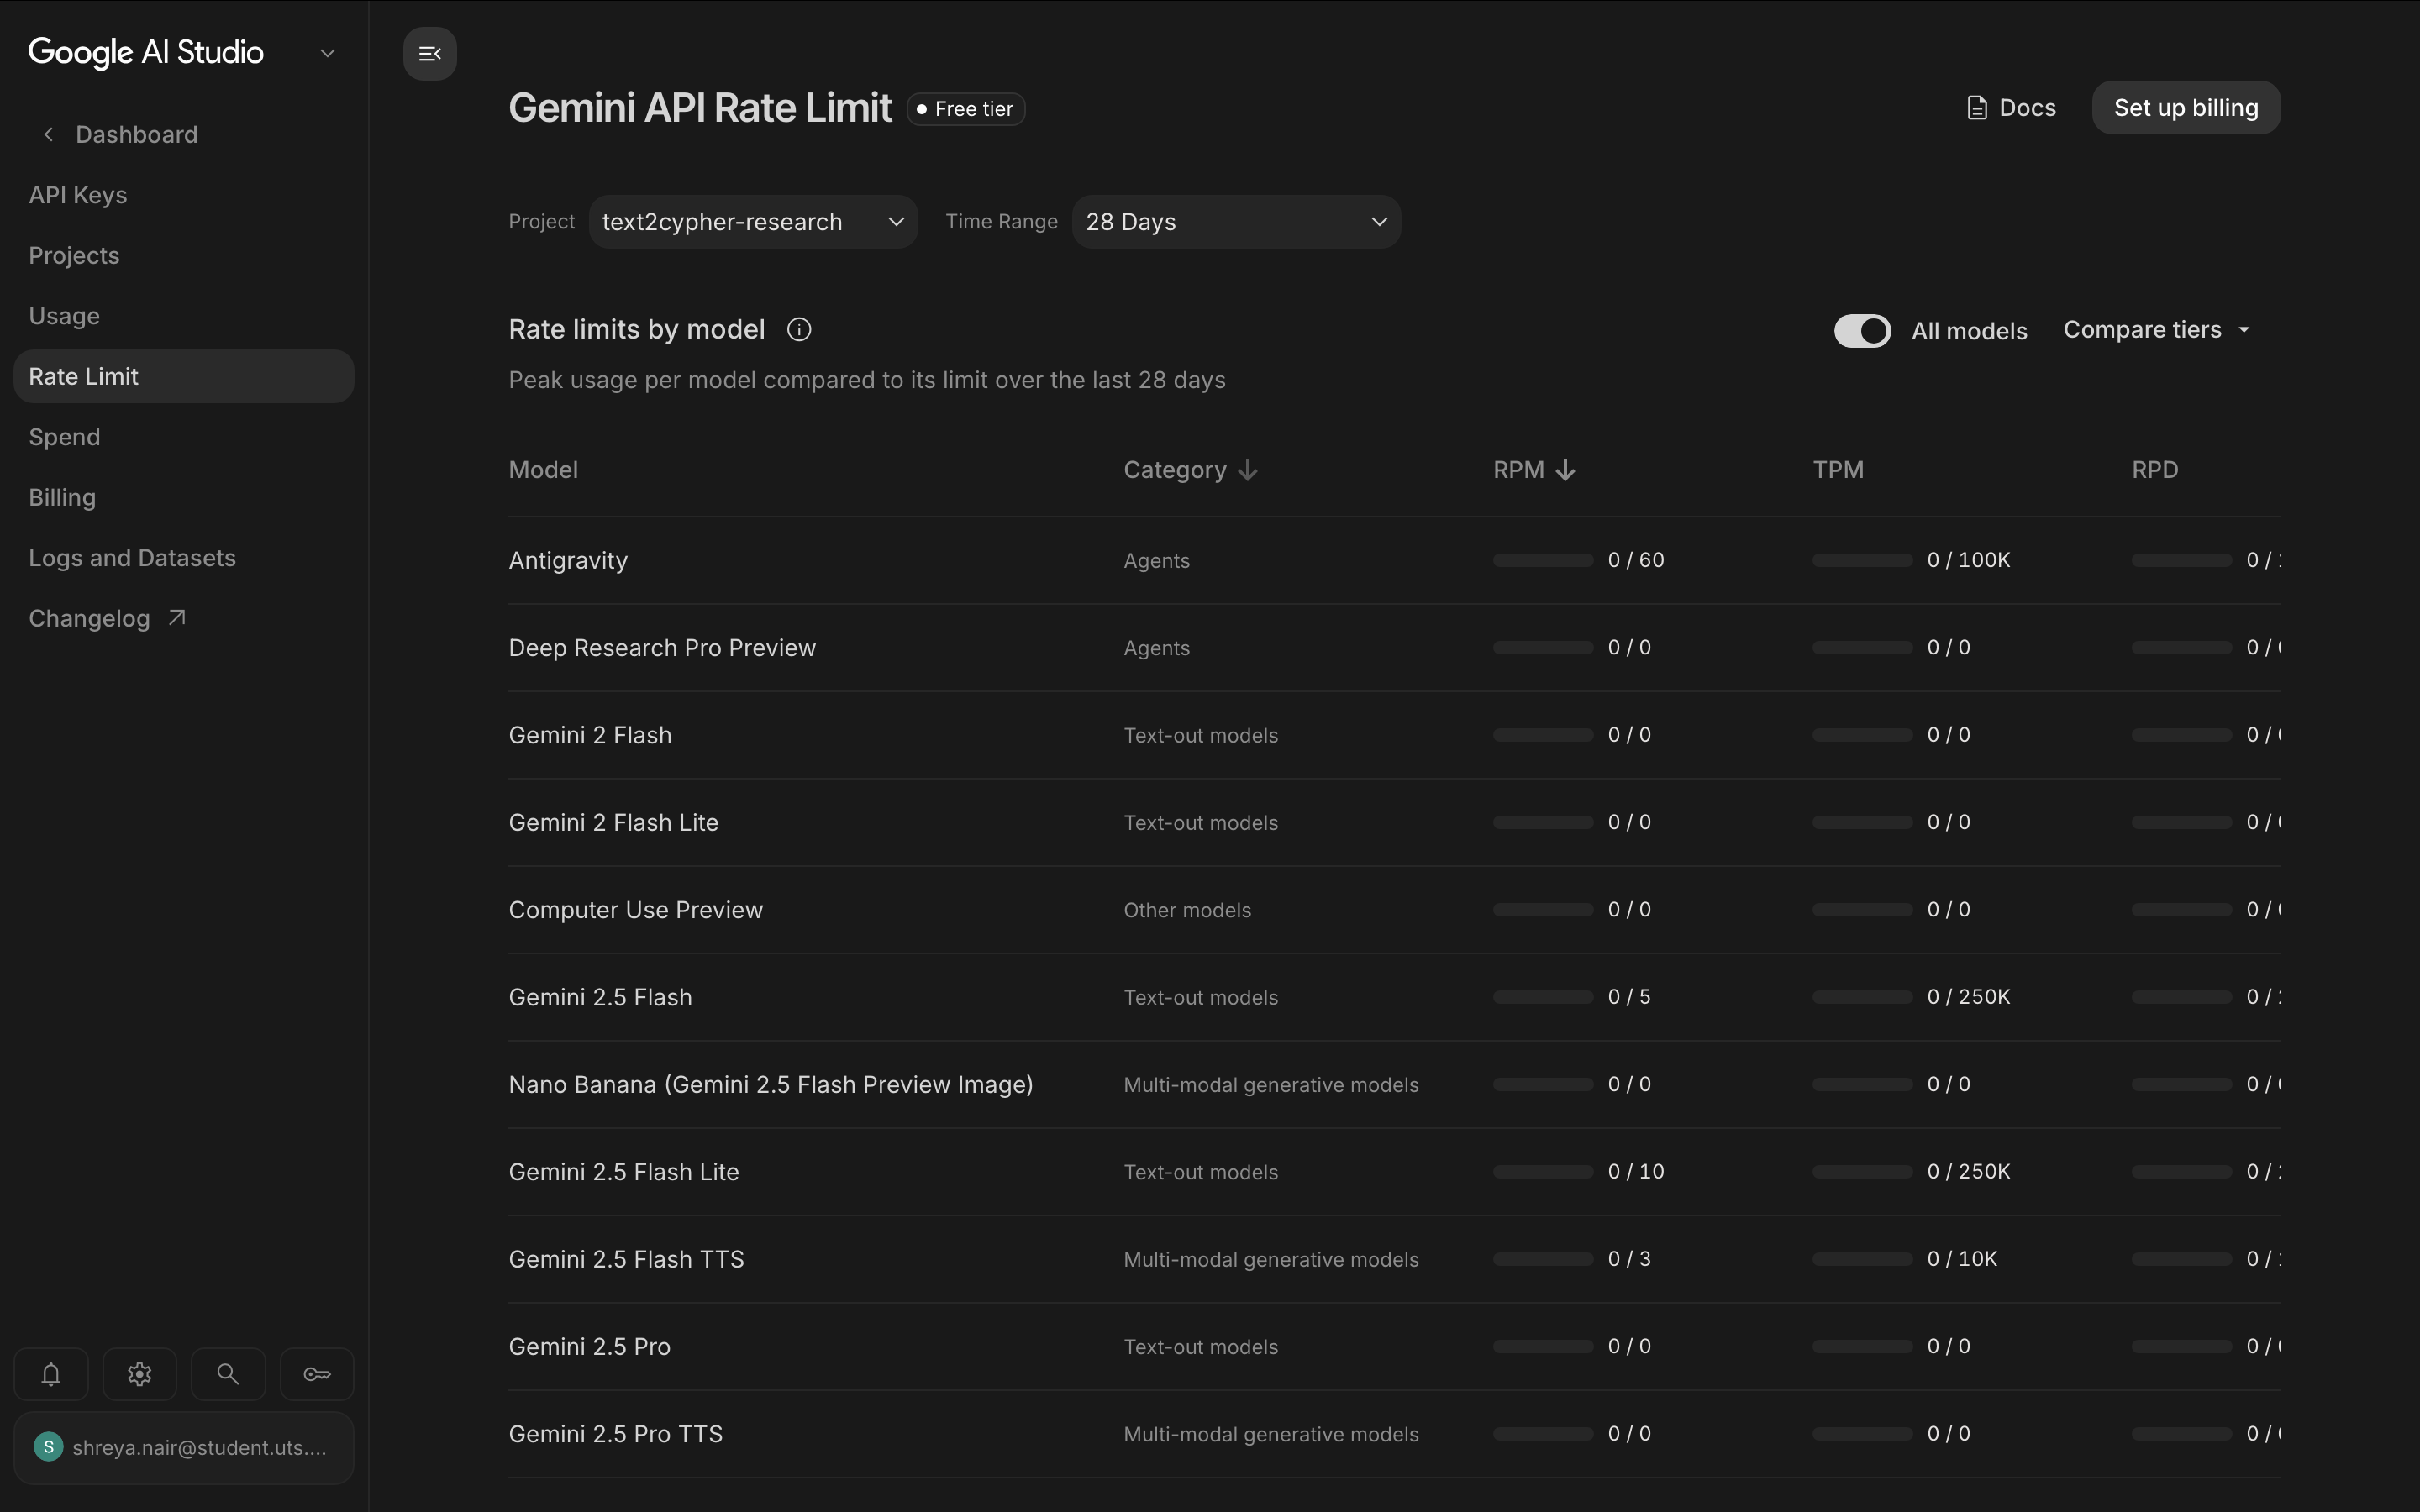

**Problem 4 — .env file not saving**  
The .env file was not being created properly through VS Code.  
Fix: Created it directly in terminal using echo command.


---

**First successful Gemini query**  
After fixing all errors, ran test_gemini.py with 
gemini-2.5-flash-lite and got back a real Cypher query.

Question given to Gemini:  
"Which 3 countries have the most entities linked to them?"

Schema given:  
(:Entity)-[:LOCATED_IN]->(:Country)

Gemini returned:
```cypher
MATCH (e:Entity)-[:LOCATED_IN]->(c:Country)
RETURN c.name, count(e) AS entityCount
ORDER BY entityCount DESC
LIMIT 3
```

This query looks correct to me — it finds the right 
relationships, counts them, sorts largest first, and 
limits to 3. No obvious errors.

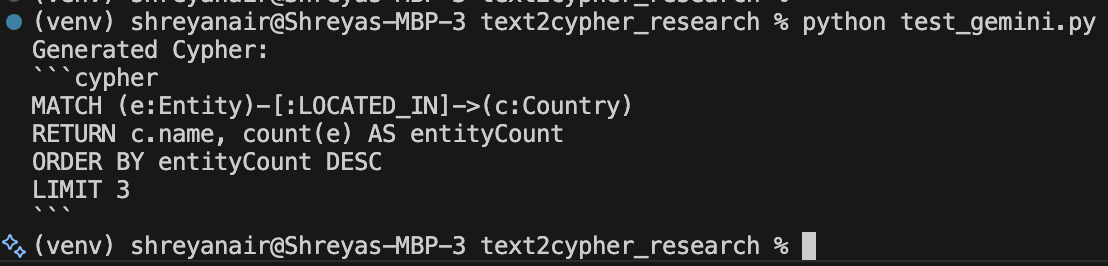

---

### Scope change — documented
Original plan used GPT-4o but that costs money.  
Switched to Gemini 2.5 Flash Lite — free, capable, 
works via API just like the original plan.  
Research questions are not affected by this change.

---

### Files in my project today

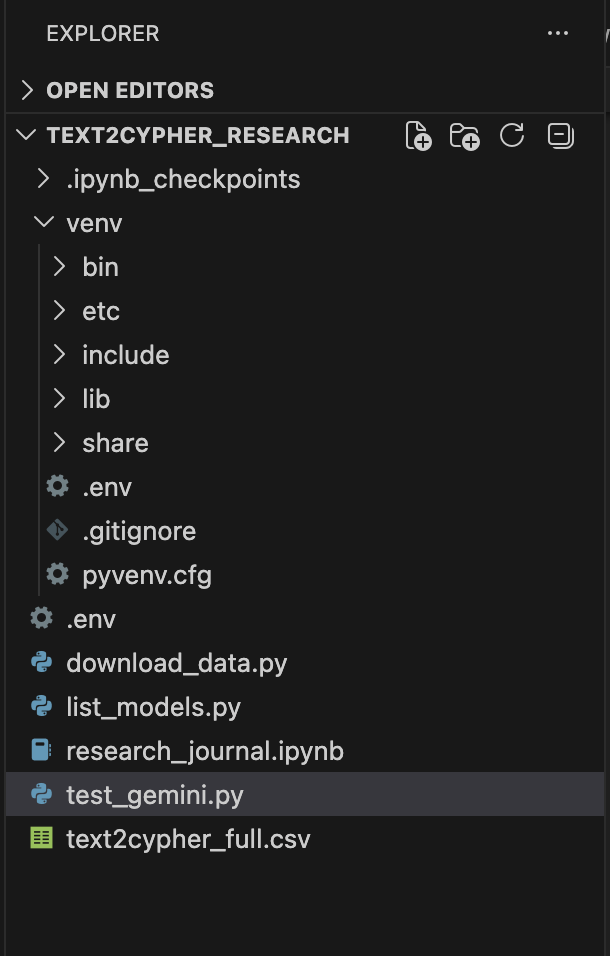

---

### Next session (July 2)
- Write stratified sampling script
- Select 200 questions from the dataset across 
  different complexity levels
- Save as a new CSV file ready for Gemini to process

## Entry 3 — 2 July 2026
**Session duration:** 1.5 hours  
**Phase:** Phase 2 — Dataset Preparation  
**Goal:** Explore dataset and create stratified sample of 200 questions

---

### What I did and why

**Dataset Exploration**  
Before sampling I needed to understand what the dataset 
actually looks like — how complex the questions are, 
how many sources they come from, and what patterns exist.

Ran explore_dataset.py to analyse the full 39,554 rows.

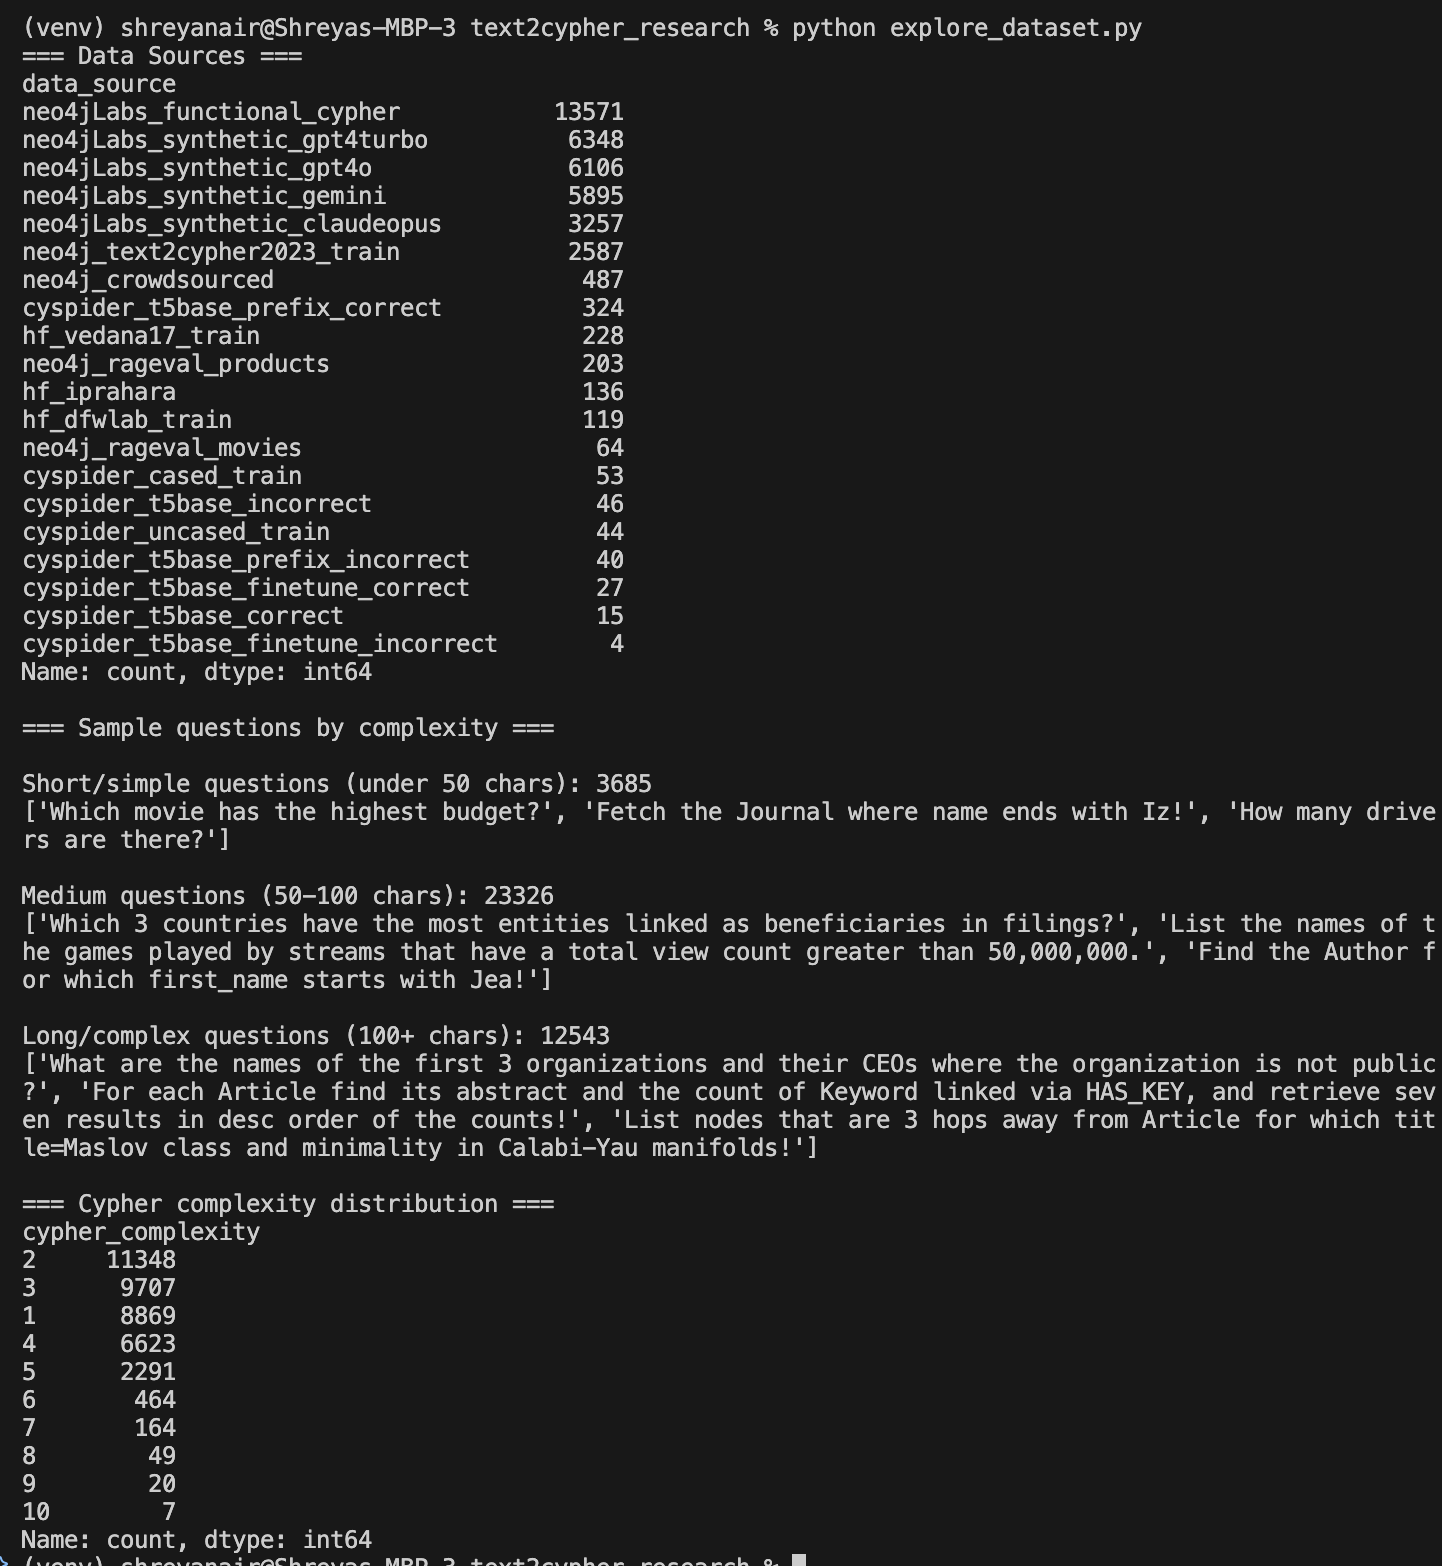

**Key findings from exploration:**
- 20 different data sources in the dataset
- Sources include real Neo4j labs queries AND synthetic 
  ones generated by GPT-4o, Gemini, and Claude Opus
- Three natural complexity levels based on question length:
  - Simple (under 50 chars): 3,685 questions
  - Medium (50-100 chars): 23,326 questions  
  - Complex (100+ chars): 12,543 questions
- Cypher complexity scores range from 1 to 10 keywords 
  — most queries score 2-3 (moderate complexity)

---

**Why stratified sampling?**  
If I just randomly picked 200 questions I might accidentally 
get mostly medium ones and miss the edge cases — very simple 
queries and very complex multi-hop ones. Stratified sampling 
means I deliberately pick a controlled mix so my results 
represent the full range of what the AI faces in real use.

Think of it like taste-testing a restaurant menu — you would 
not just try 200 versions of the same dish. You would try 
starters, mains, and desserts so you can judge the whole menu.

---

**Stratified Sample — 200 questions selected**  
Wrote stratified_sample.py and ran it successfully.

Sample breakdown:
- Simple questions: 50
- Medium questions: 100  
- Complex questions: 50
- Total: 200

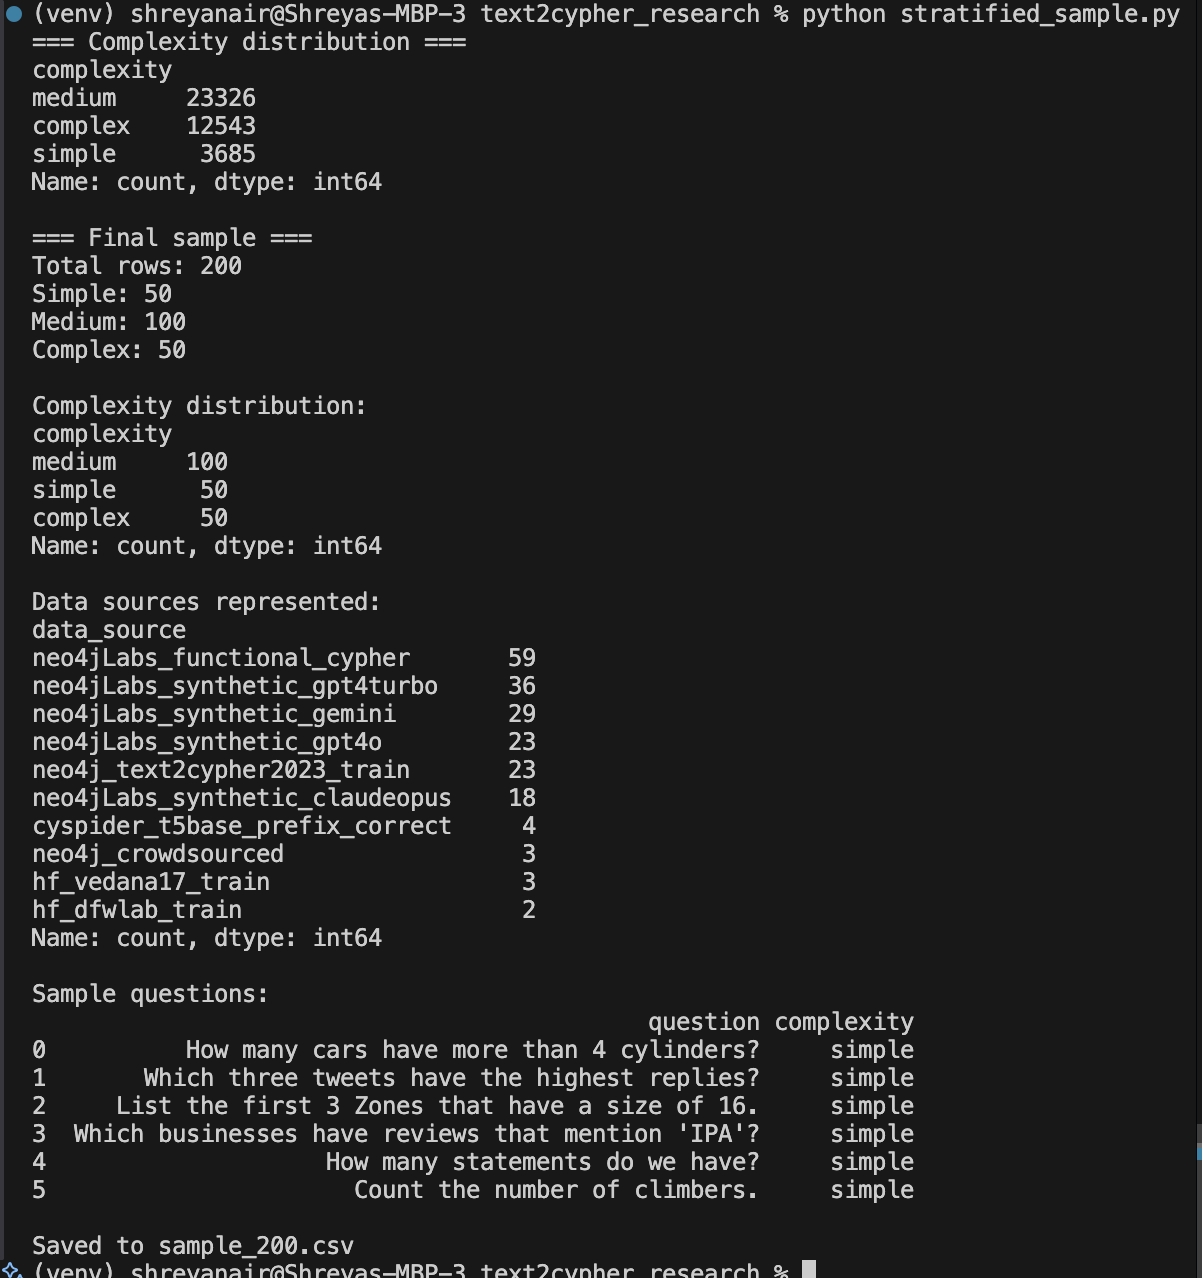

**Important detail — random_state=42**  
This number makes the sampling reproducible. Anyone 
running this script will get the exact same 200 questions. 
This is important for research integrity — my results 
can be verified.

**Data sources in sample:**
- neo4jLabs_functional_cypher: 59 (real hand-written queries)
- neo4jLabs_synthetic_gpt4turbo: 36
- neo4jLabs_synthetic_gemini: 29
- neo4jLabs_synthetic_gpt4o: 23
- neo4j_text2cypher2023_train: 23
- Plus 5 other sources

Having 10 different sources means my sample is not biased 
towards one style of question.

---

**Output saved:**  
sample_200.csv — 200 stratified questions ready for 
Gemini to process

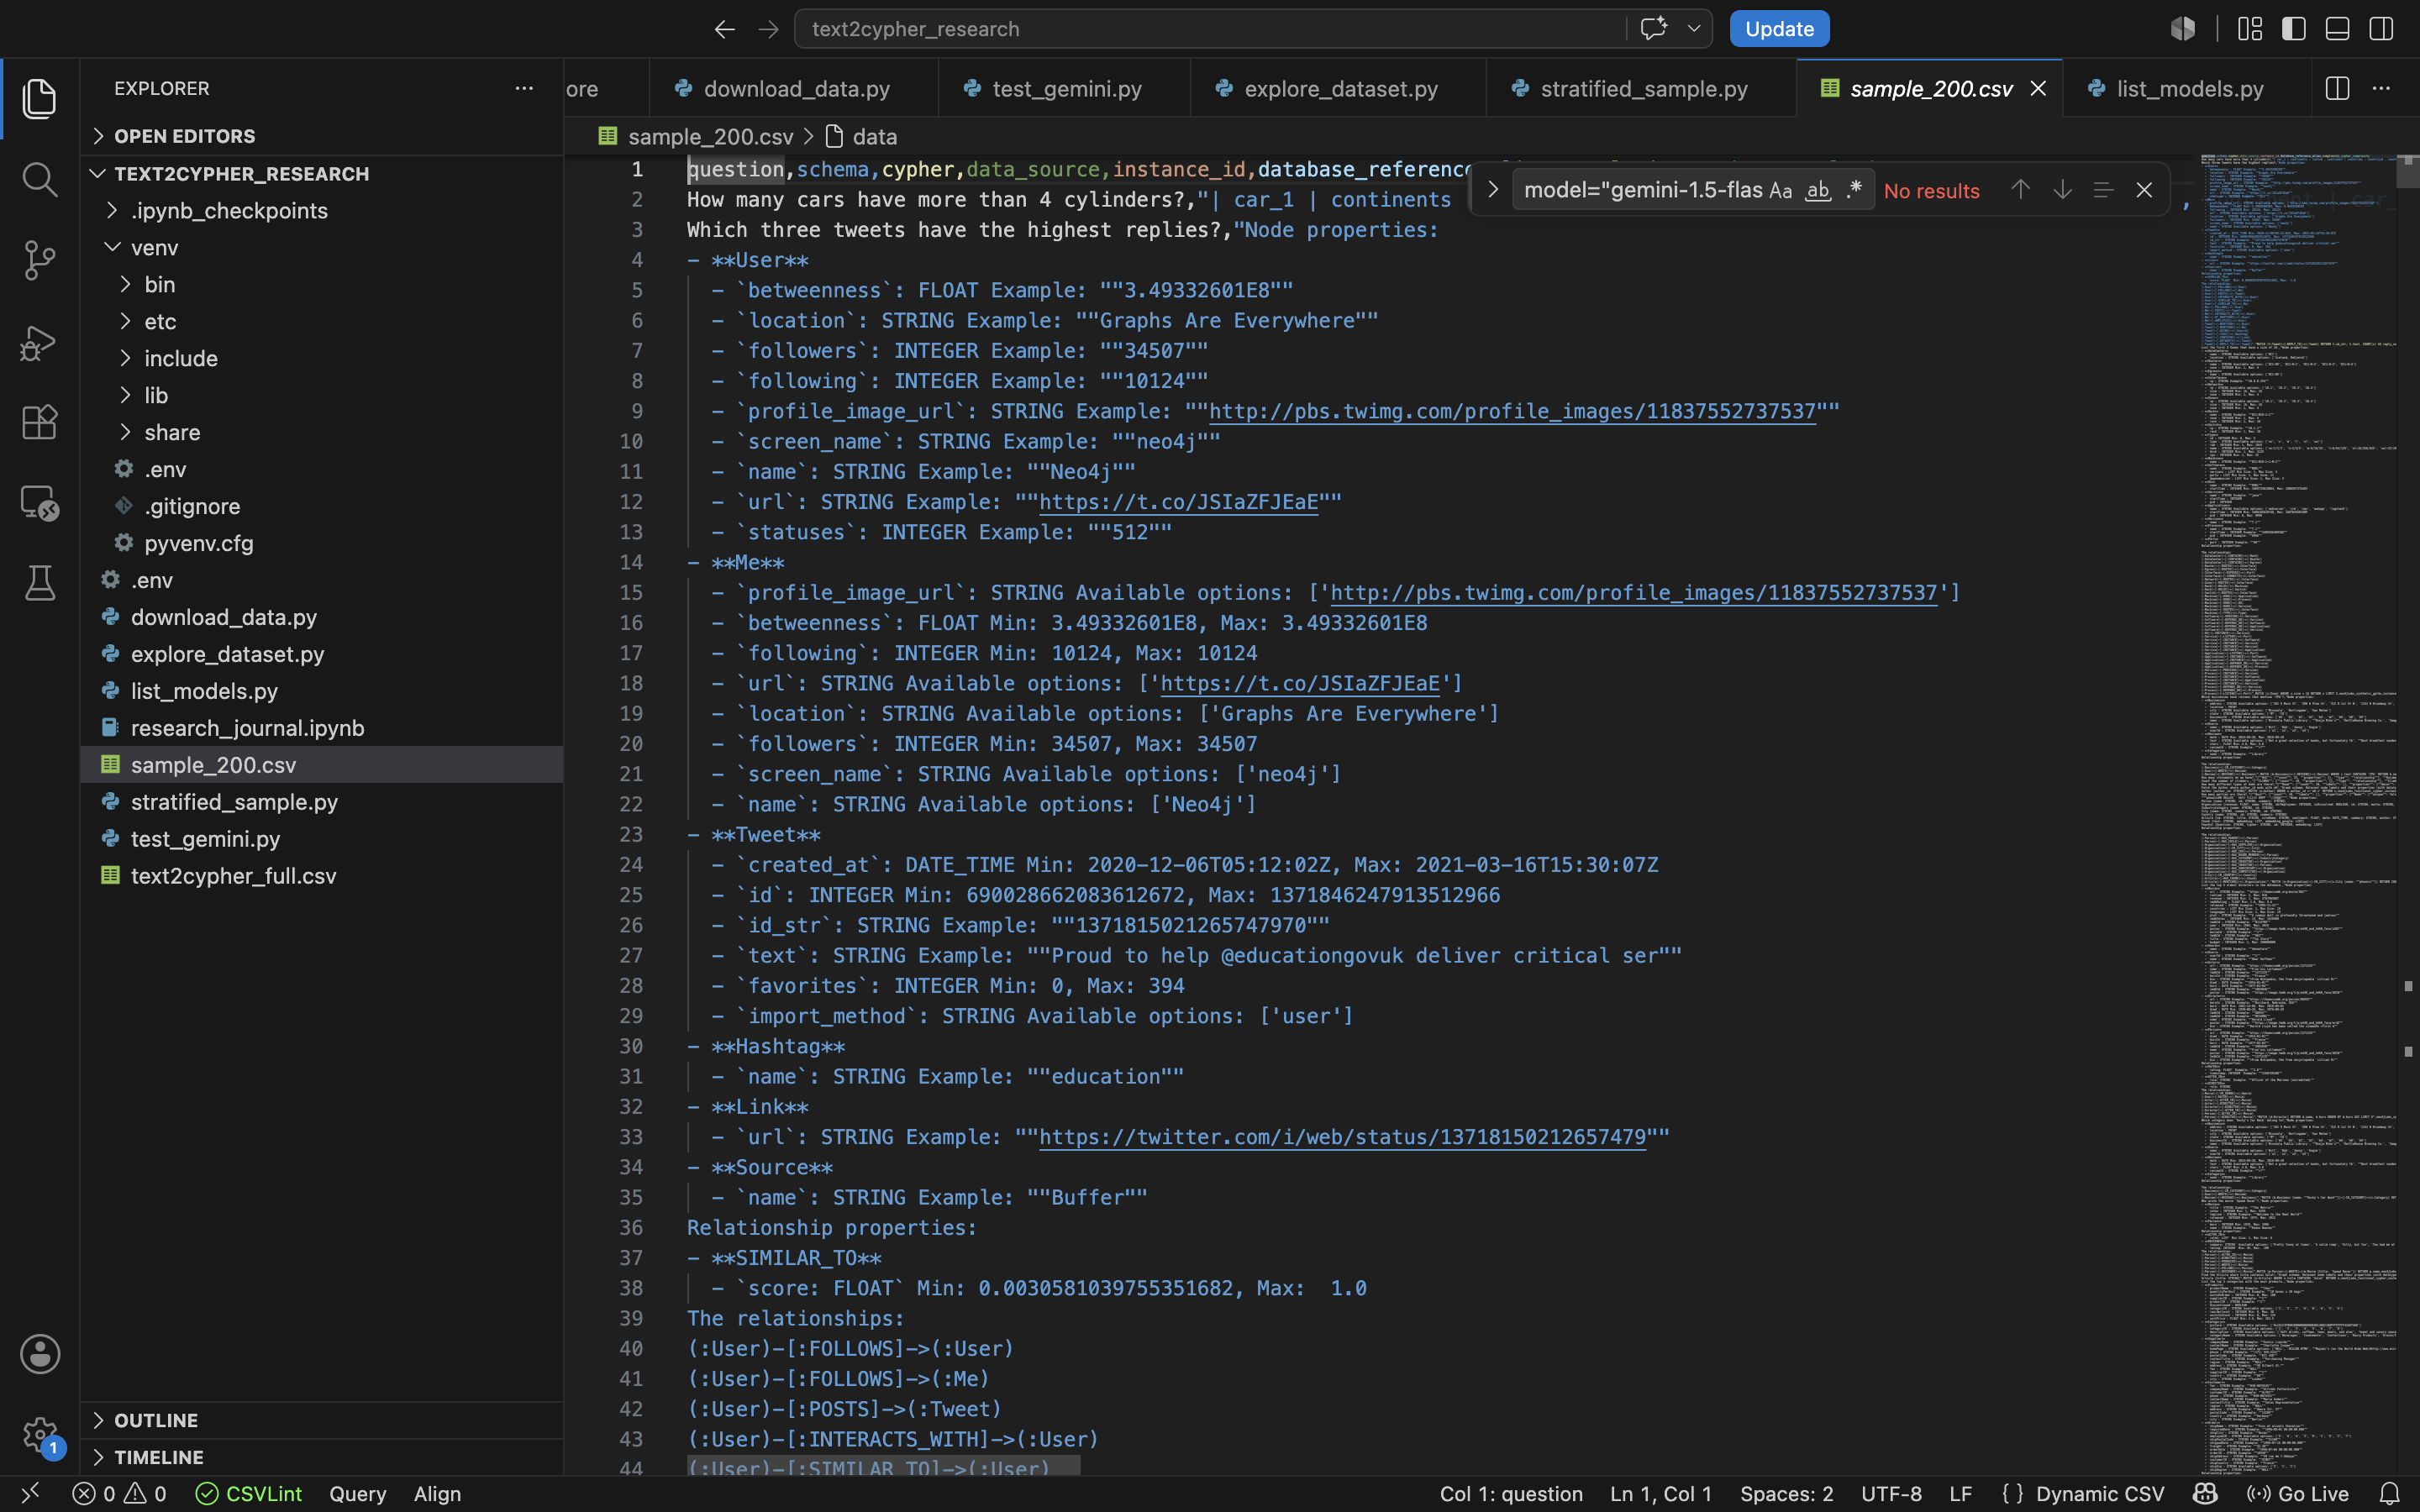

---

### Files created this session
| File | Purpose |
|---|---|
| explore_dataset.py | Analyses full dataset structure |
| stratified_sample.py | Creates 200 question stratified sample |
| sample_200.csv | Final 200 questions ready for processing |

---

### What I need to do on July 3
- Send all 200 questions to Gemini and collect 
  generated Cypher queries
- Compute BLEU and Exact Match scores for each query
- Save everything into one structured dataset
- This is the biggest coding task so far

### Status vs timeline
- Phase 1 Setup: Complete
- Phase 2 Dataset & Query Generation: In progress
- On track for July deadline

## Entry 3 — 2 July 2026
**Session duration:** 1.5 hours  
**Phase:** Phase 2 — Dataset Preparation  
**Goal:** Understand the dataset structure and 
create a stratified sample of 200 questions

---

### What I did and why

#### Task 1 — Dataset Exploration
Before picking my 200 questions I needed to understand 
what the full dataset actually looks like. Just grabbing 
200 random rows could mean I accidentally test only easy 
questions and miss the harder ones entirely.

Ran explore_dataset.py to analyse all 39,554 rows.

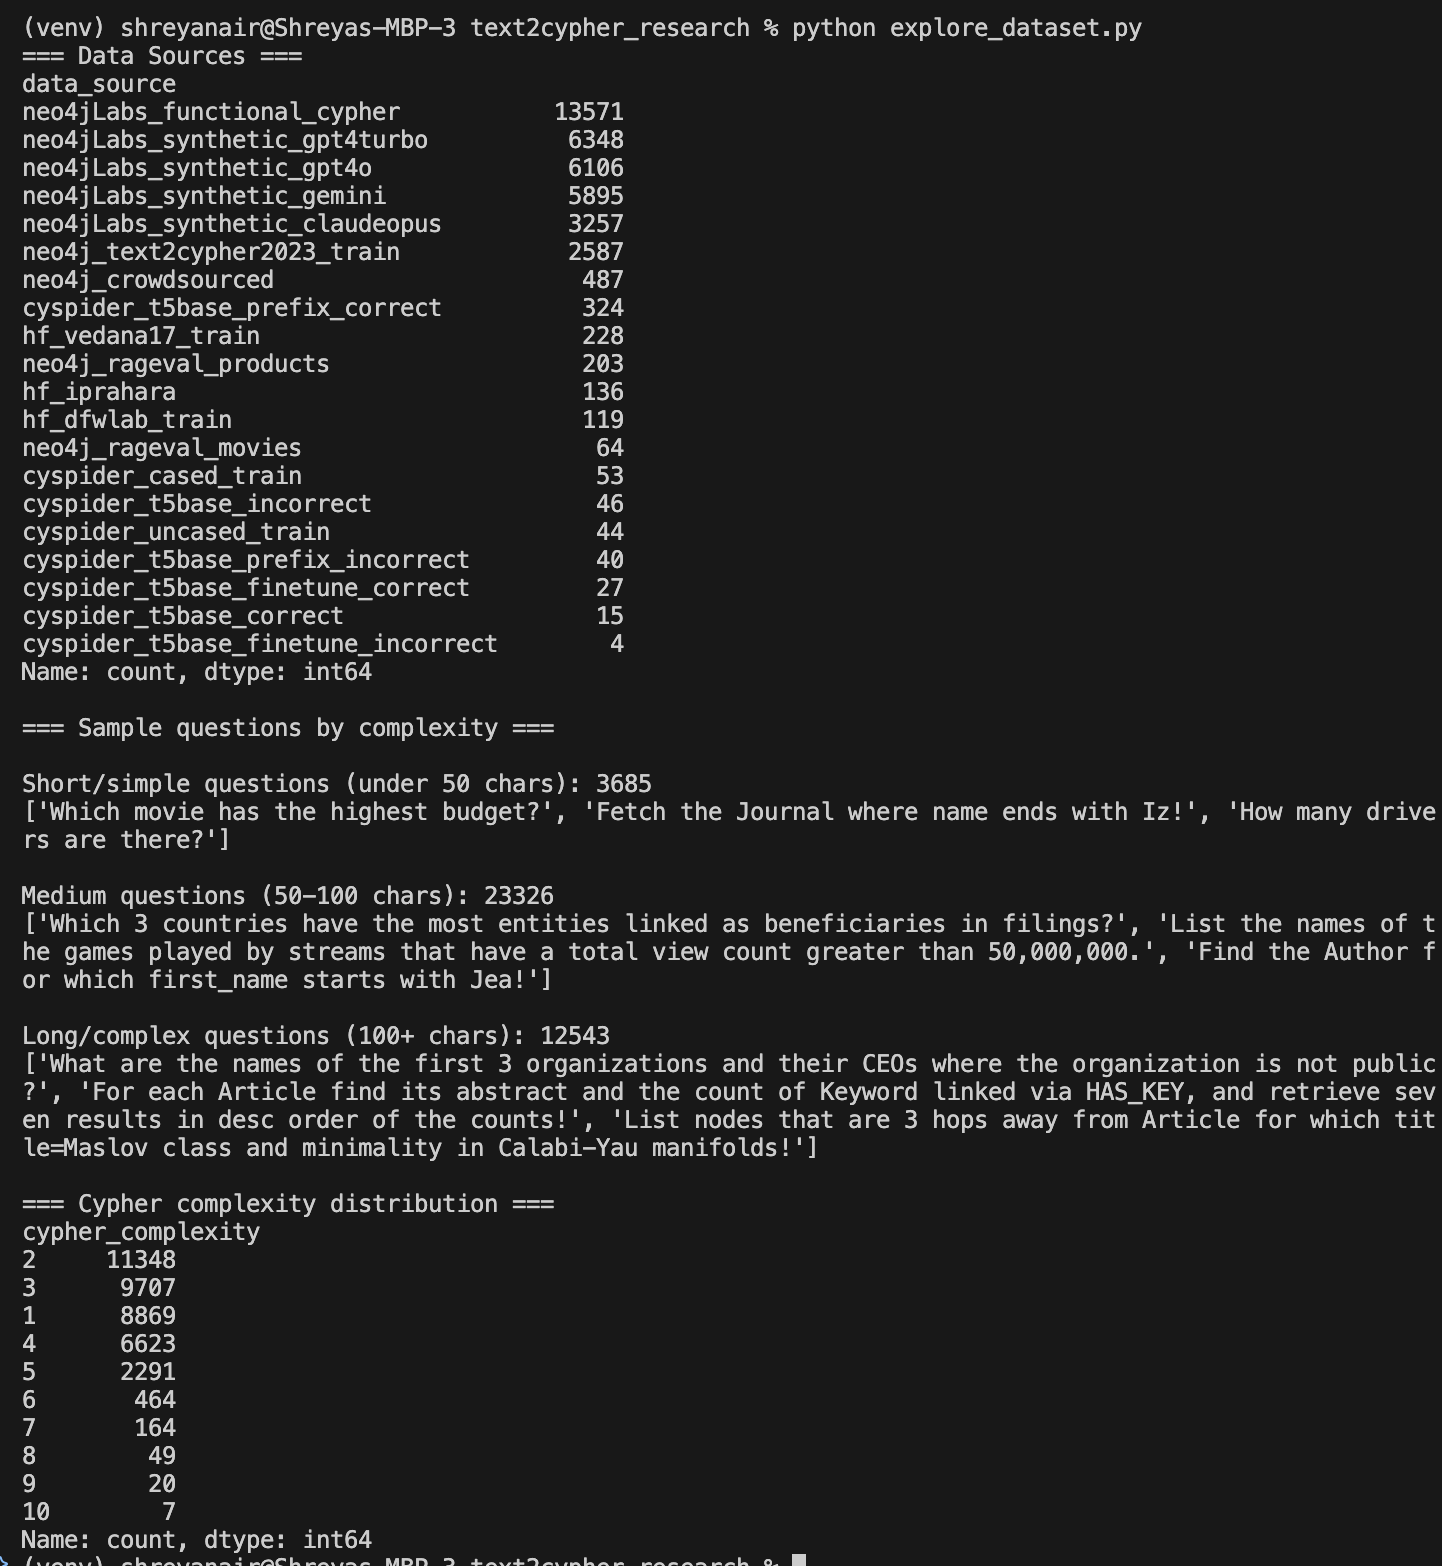

**What I found:**
- 20 different data sources — real Neo4j queries mixed 
  with synthetic ones made by GPT-4o, Gemini, and Claude
- Three natural complexity levels:
  - Simple (under 50 characters): 3,685 questions
  - Medium (50-100 characters): 23,326 questions
  - Complex (100+ characters): 12,543 questions
- Cypher complexity scores range from 1 to 10 — most 
  queries use 2-3 keywords like MATCH, WHERE, LIMIT

---

#### Task 2 — Stratified Sampling
Instead of random sampling I used stratified sampling — 
deliberately picking a controlled mix across all three 
complexity levels.

Think of it like taste testing a restaurant menu. You 
would not try 200 versions of the same dish. You would 
try starters, mains and desserts to judge the full menu.

**Sample breakdown:**
- Simple: 50 questions
- Medium: 100 questions
- Complex: 50 questions
- Total: 200 questions

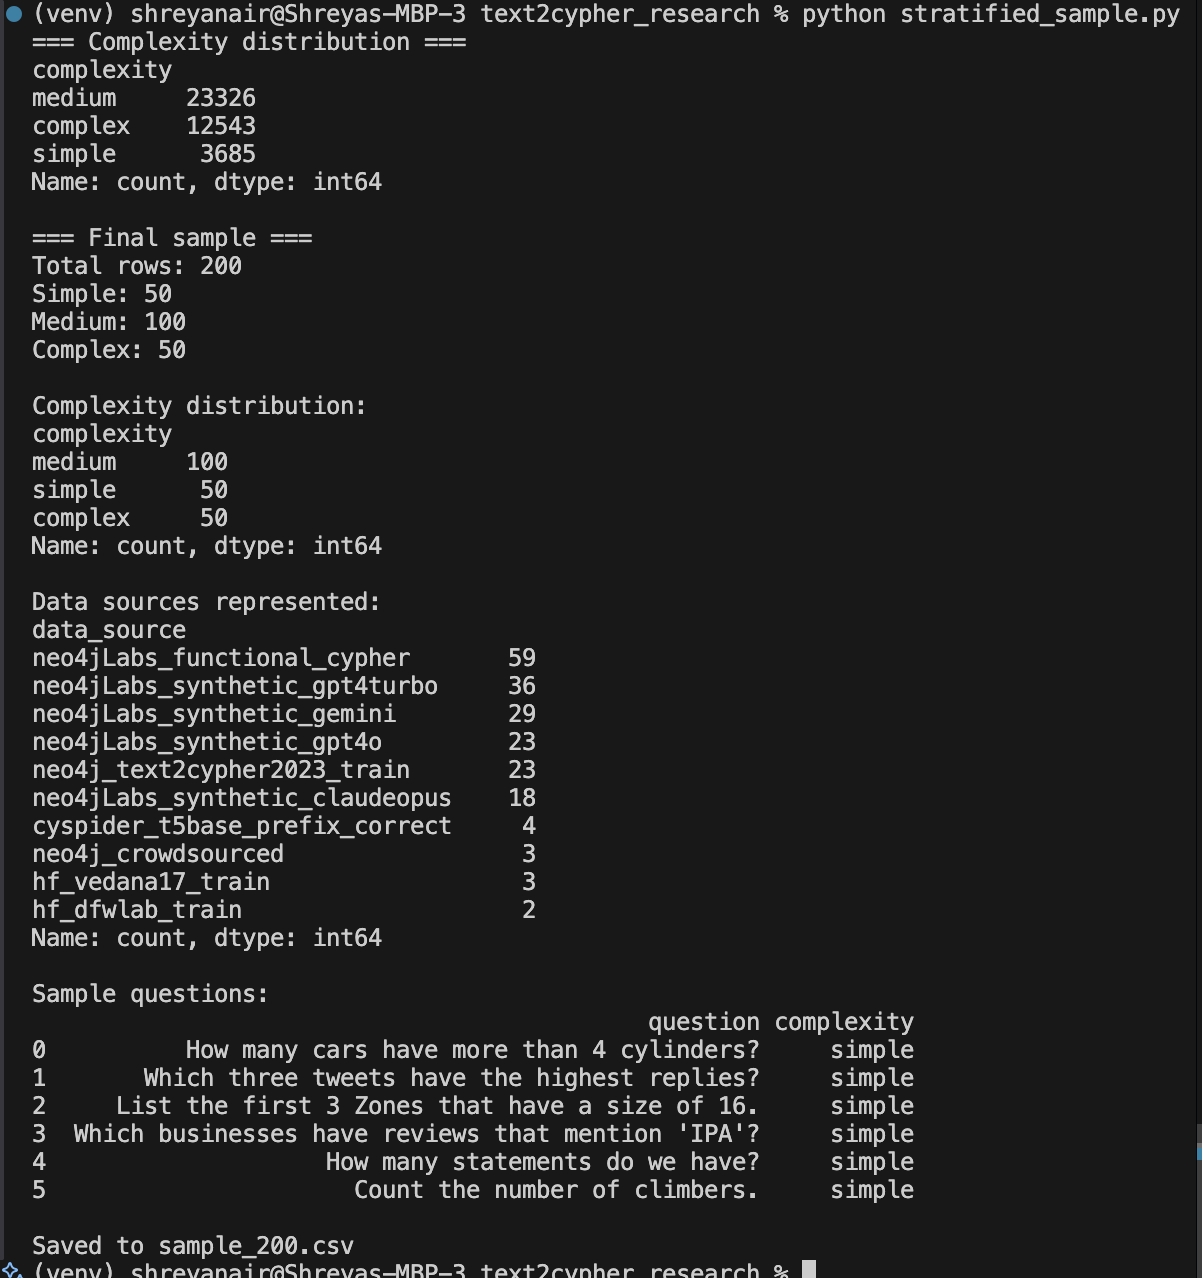

**Key decision — random_state=42**  
This number locks the random selection so it is 
reproducible. Anyone running this script gets the exact 
same 200 questions. This matters for research integrity 
— my supervisor or another researcher can verify my 
results exactly.

**Data sources in my 200:**
- neo4jLabs_functional_cypher: 59 (real hand-written)
- neo4jLabs_synthetic_gpt4turbo: 36
- neo4jLabs_synthetic_gemini: 29
- neo4jLabs_synthetic_gpt4o: 23
- neo4j_text2cypher2023_train: 23
- 5 other sources

10 different sources means my sample is not biased 
towards any one style of question.

---

### Output saved
sample_200.csv — 200 stratified questions ready for 
Gemini to process in the next session

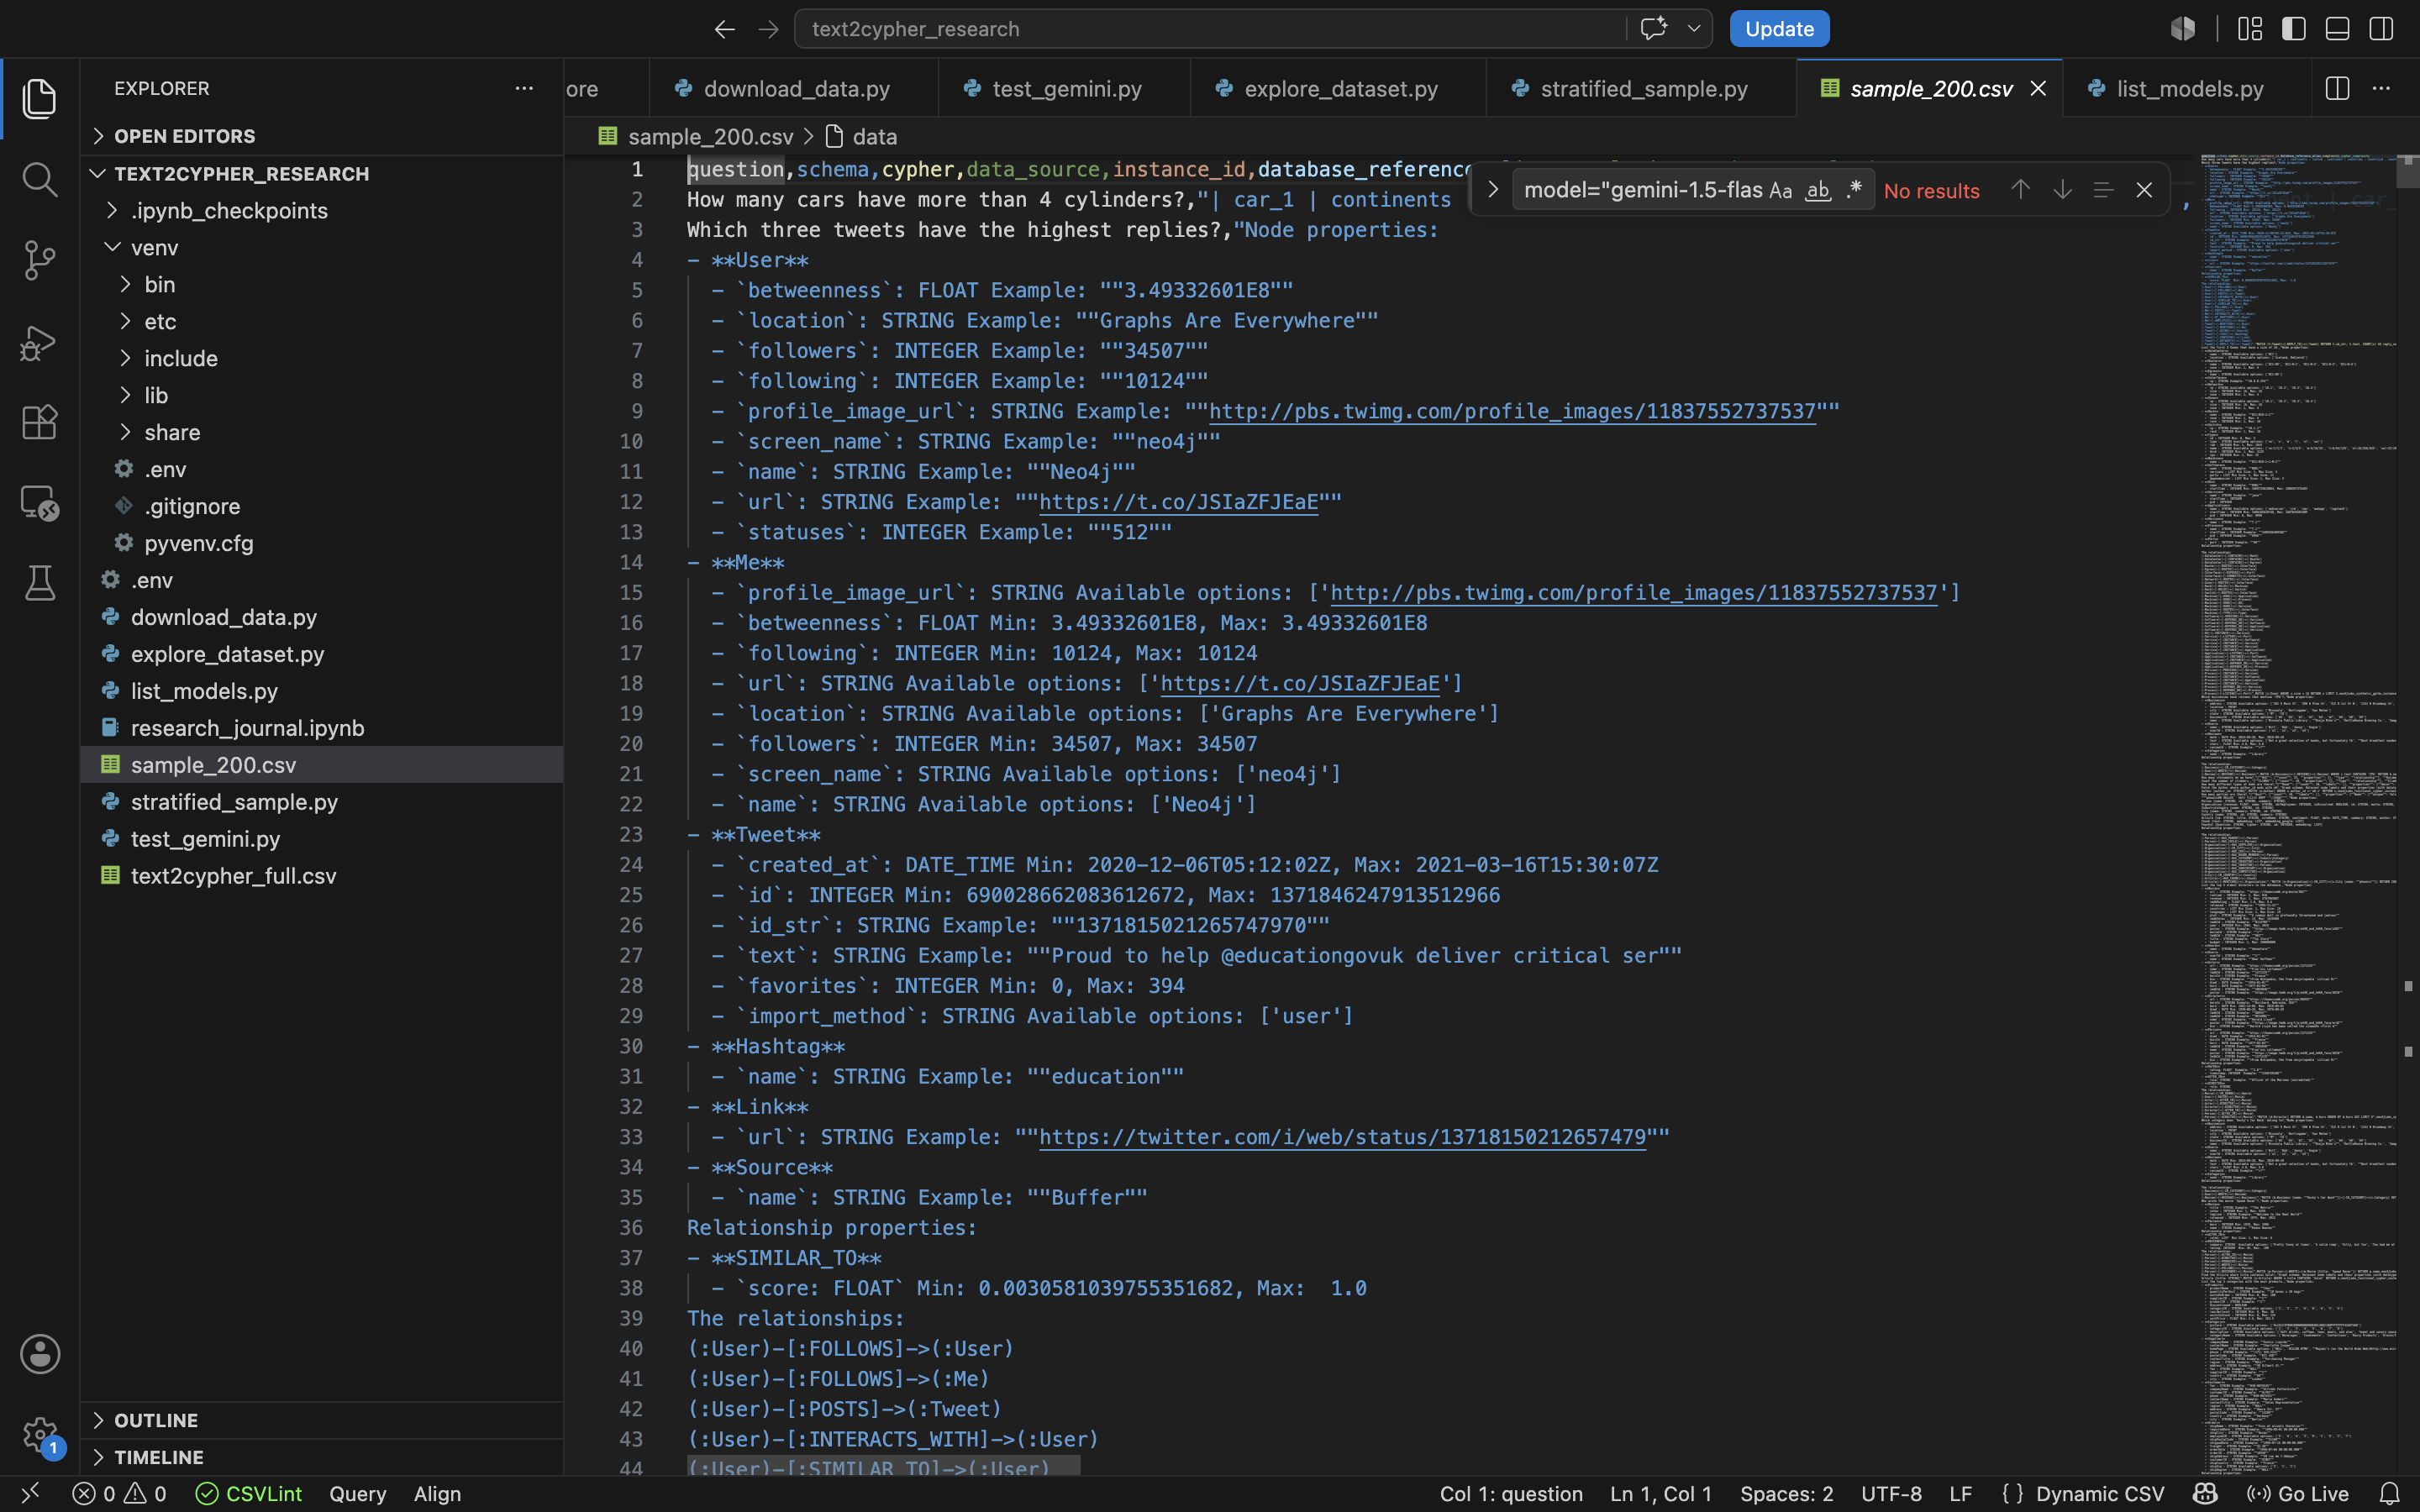

---

### Files created this session
| File | Purpose |
|---|---|
| explore_dataset.py | Analyses full dataset structure and complexity |
| stratified_sample.py | Creates reproducible 200 question sample |
| sample_200.csv | Final stratified sample ready for generation |

---

### What I need to do next — July 3
- Send all 200 questions to Gemini one by one
- Collect the generated Cypher query for each
- Compute BLEU and Exact Match scores
- Save everything into generated_queries.csv

### Status vs timeline
- ✅ Phase 1 Setup: Complete
- 🔄 Phase 2 Dataset Preparation: Complete
- 🔄 Phase 2 Query Generation: Starting July 3
- ✅ On track

## Entry 4 — 3 July 2026
**Session duration:** 2 hours  
**Phase:** Phase 2 — Query Generation begins  
**Goal:** Build query generation script and run first batch

---

### What I did and why

#### Task 1 — Built the query generation script
Created scripts/generate_queries.py — the most important
script in the project. This script:
- Reads each of the 200 questions from sample_200.csv
- Sends each question to Gemini with the graph schema
- Receives the generated Cypher query back
- Computes BLEU score comparing generated vs reference
- Computes Exact Match score
- Saves progress every 10 rows in case of interruption
- Resumes automatically from where it stopped

The resumable design was a deliberate engineering decision
— API calls can fail at any point and losing progress
would waste quota and time.

---

#### Task 2 — First batch of 20 queries processed

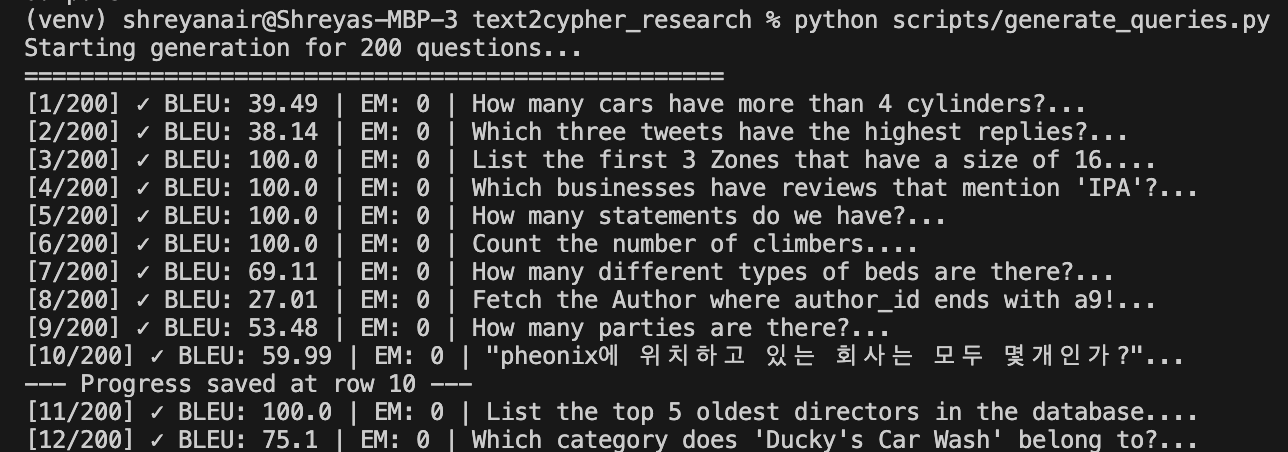

**Early results from first 20 queries:**
- Several queries scored BLEU 100 but Exact Match 0
- This means Gemini generated a query that looks identical
  to the reference by BLEU scoring but does not match exactly
- This is the first real evidence supporting RQ2

**Example from first batch:**
- Row 3: BLEU 100.0, EM 0
- Row 4: BLEU 100.0, EM 0
- Row 5: BLEU 100.0, EM 0

These queries score perfectly on BLEU but are not exact
matches — proving BLEU cannot reliably confirm correctness.

---

#### Task 3 — Quota exhausted after 20 queries

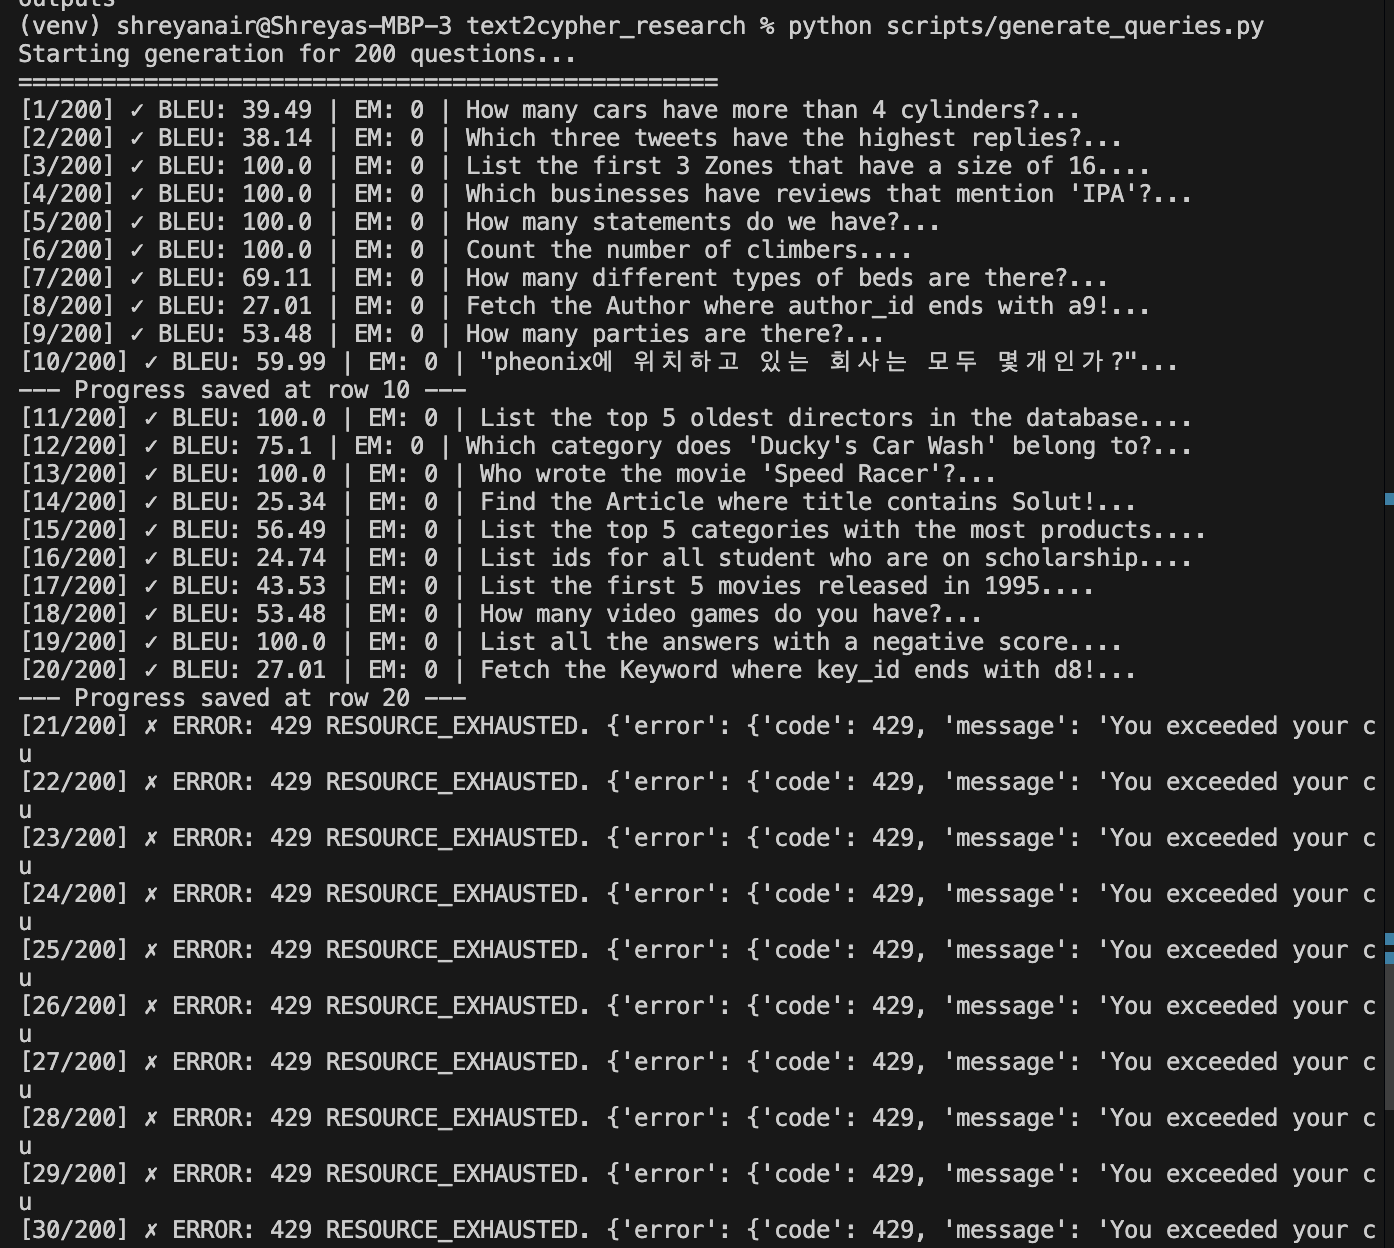

Free tier daily limit reached after 20 queries.
Script saved progress automatically and stopped cleanly.
Resumable design worked exactly as intended.

**Decision made:** Continue running script daily until
all 200 queries are complete. Each day adds 20 more rows.

---

### Files created this session
| File | Purpose |
|---|---|
| scripts/generate_queries.py | Main query generation pipeline |
| data/generated_queries.csv | Results saved with progress |

---

### What I need to do next — July 5
- Move to iHPC for better RAM and performance
- Resolve API quota issues
- Complete all 200 queries

### Status vs timeline
- Phase 1 Setup: Complete
- Phase 2 Query Generation: Started — 20/200 done
- On track

## Entry 5 — 5 July 2026
**Session duration:** 3 hours  
**Phase:** Phase 2 — Query Generation Complete  
**Goal:** Set up iHPC, transfer files, run all 200 queries

---

### What I did and why

#### Task 1 — Connected VS Code to UTS iHPC
Instead of running everything on my MacBook Pro M2 (8GB RAM),
I connected to UTS iHPC (mars7 node) which has 188GB RAM.
This solved the memory freezing issue I was experiencing locally.

Connected via Remote SSH extension in VS Code directly to
ihpc.research.uts.edu.au then moved to mars7 compute node.


---

#### Task 2 — Set up conda environment on mars7
iHPC uses Python 3.6 by default which is too old. Used
Miniconda (already installed on iHPC) to create a fresh
Python 3.12 environment called text2cypher.

```bash
conda create -n text2cypher python=3.12
conda activate text2cypher
pip install pandas sacrebleu google-genai python-dotenv
```

---

#### Task 3 — Transferred project files to iHPC
Copied entire project folder from MacBook to iHPC using
VS Code drag and drop. Cleaned up duplicate folder structure
that was created during transfer.

Final clean structure on iHPC:
- data/ — sample_200.csv, generated_queries.csv
- scripts/ — all Python scripts
- pipeline/ — for classifiers (next phase)
- analysis/ — for statistical analysis
- outputs/ — for final charts and tables
- journal_screenshots/ — all session screenshots

---

#### Task 4 — Resolved Gemini API issues
Several issues encountered and resolved:

**Issue 1 — Daily quota exhausted (429 error)**
Free tier only allows 20 requests per day on most models.
Fix: Added $25 AUD to Google Cloud billing. Discovered
$434.03 in existing free GCP credits — card charged but
credits cover all usage.

**Issue 2 — Model consistency decision**
Started with gemini-2.5-flash-lite then switched to
gemini-3.1-flash-lite for higher daily limits (500 RPD).
Decision: Restart all 200 queries fresh on gemini-3.1-flash-lite
for consistency. One model, clean methodology.

**Issue 3 — Per-minute rate limits (429 error)**
Even with paid tier, models have RPM limits.
Fix: Added 120 second automatic wait on 429 errors,
5 second wait between each request.

---

#### Task 5 — All 200 queries generated successfully 

All 200 queries complete
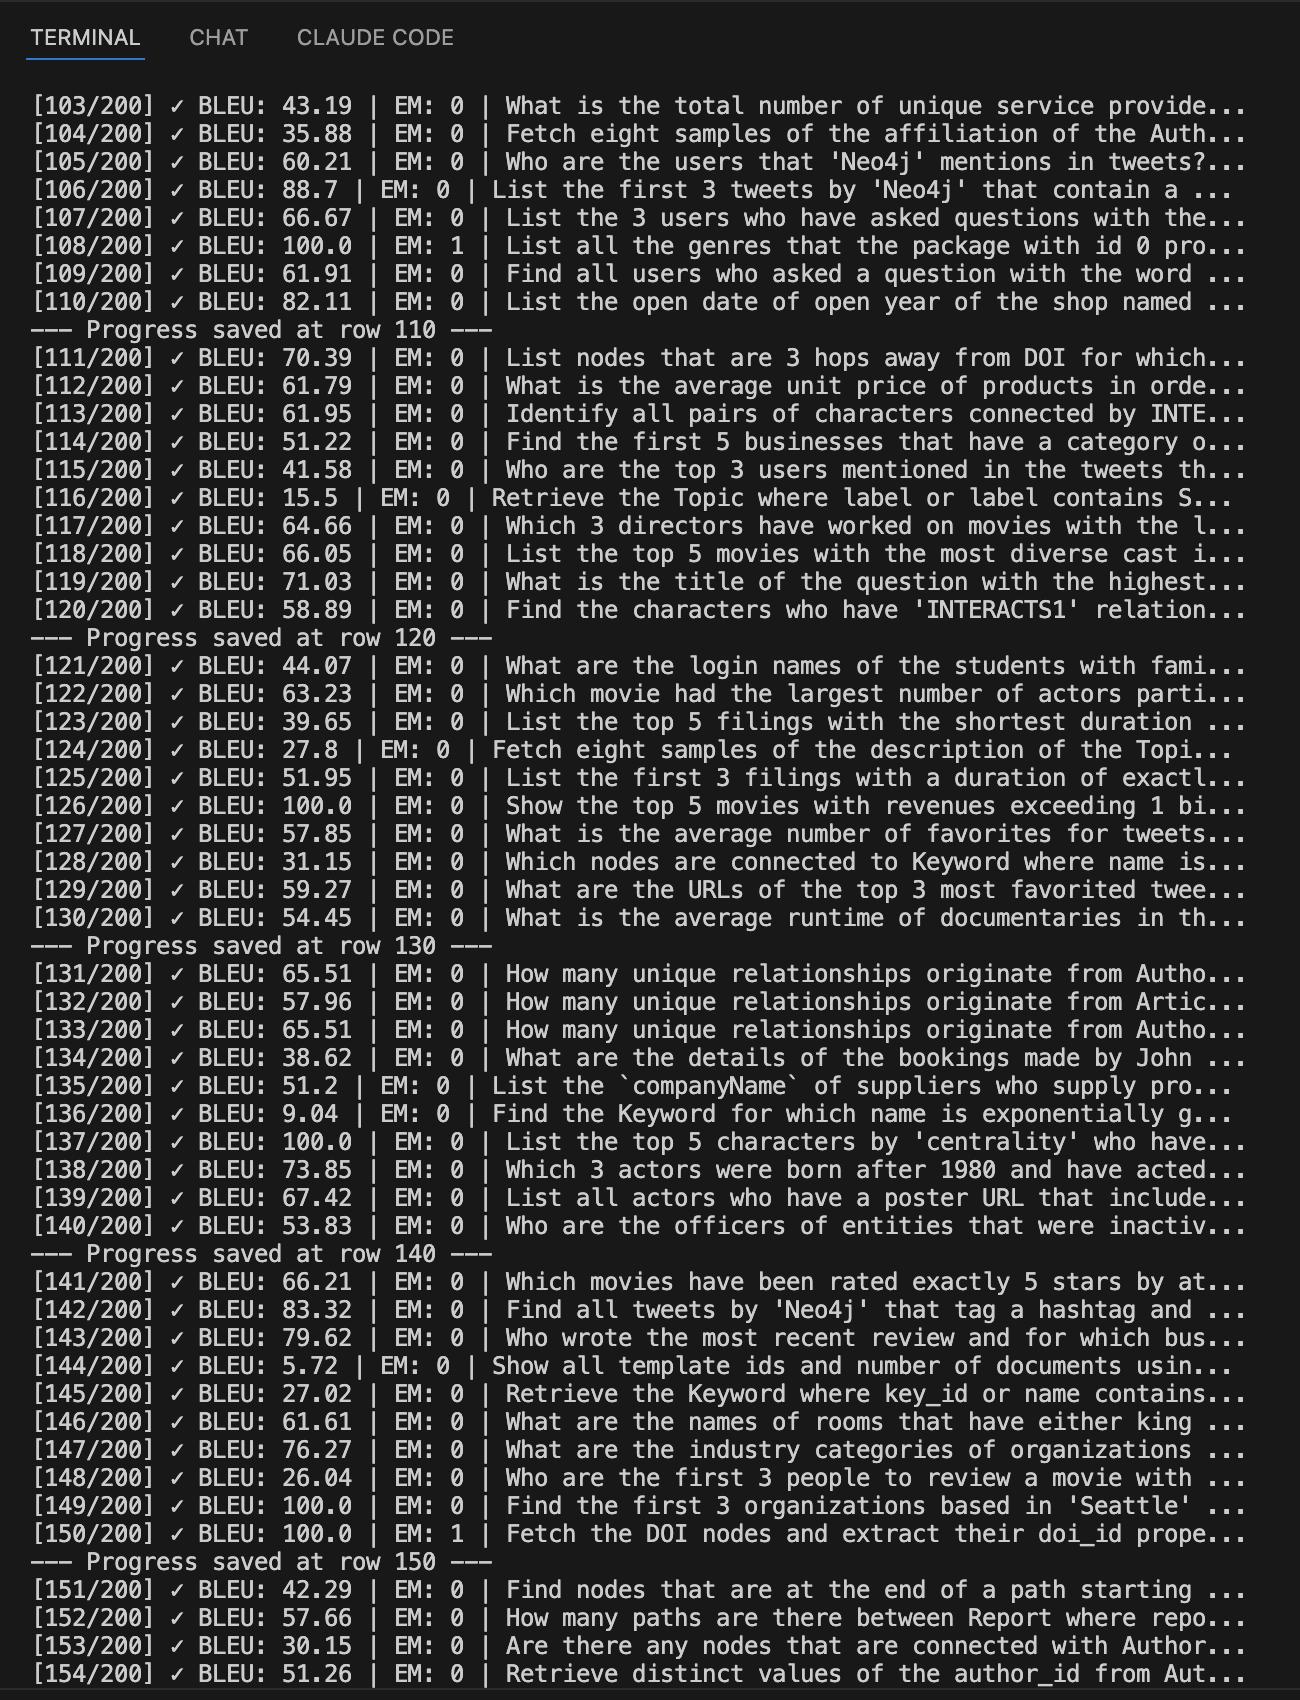
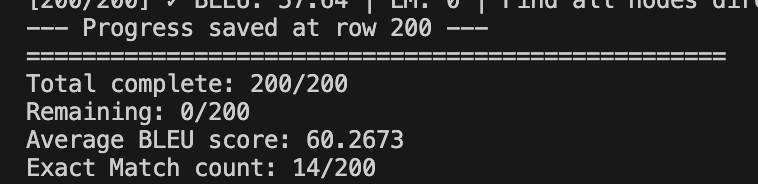

**Final results:**

| Metric | Result |
|---|---|
| Total queries generated | 200/200 |
| Model used | Gemini 3.1 Flash Lite |
| Average BLEU score | 60.27 |
| Exact Match count | 14/200 (7%) |
| BLEU=100 but EM=0 | 10 queries |

**Complexity breakdown:**
| Complexity | Average BLEU |
|---|---|
| Simple | 67.77 |
| Medium | 59.68 |
| Complex | 53.94 |

Detailed results breakdown

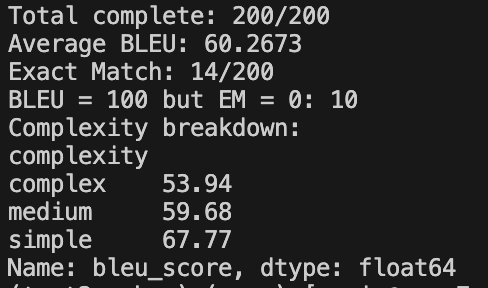

---

### Key findings from today

**Finding 1 — BLEU 100 with EM 0 observed in 10 queries**
Ten queries scored a perfect 100 on BLEU but still did not
exactly match the reference query. This directly supports
RQ2 — BLEU alone cannot reliably indicate query correctness.
A perfect similarity score does not mean a perfect query.

**Finding 2 — Complexity affects performance**
Simple queries averaged BLEU 67.77 while complex queries
averaged only 53.94. This confirms that LLM performance
degrades as query complexity increases — expected and
consistent with the literature.

**Finding 3 — Exact Match is very strict**
Only 14 out of 200 queries exactly matched the reference.
This does not mean 186 queries are wrong — many may be
logically correct but worded differently. This is exactly
why the error classification pipeline is needed.

---

### Scope note — Model formally documented
Query generation used Gemini 3.1 Flash Lite exclusively
via the Google Gemini API with zero-shot prompting.
Original proposal specified GPT-4o. Switch documented as
model-agnostic scope adjustment. Research questions
are unaffected.

---

### Files created this session
| File | Purpose |
|---|---|
| data/generated_queries.csv | All 200 queries with BLEU and EM scores |

---

### What I need to do next — July 7
- Manually inspect sample of 40 queries
- Label each with error type (syntax, schema, logical, performance)
- This manual labelling validates the automated classifier later
- Begin designing the four classifier scripts

### Status vs timeline
- ✅ Phase 1 Setup: Complete
- ✅ Phase 2 Dataset & Query Generation: Complete
- 🔄 Phase 3 Taxonomy Validation: Starting July

## Entry 6 — 10 July 2026
**Session duration:** 1.5 hours  
**Phase:** Phase 3 — Taxonomy Validation  
**Goal:** Manually label first 20 queries to validate error taxonomy

---

### What I did and why

#### What is taxonomy validation?
Before building an automated pipeline to detect errors, I need
to confirm that my 4 error categories actually show up in real
data. I read each query myself, compare it to the reference,
and decide what kind of mistake was made.

Think of it like a teacher marking exam papers before building
an auto-marking system — you need to know what mistakes look
like first.

#### The 4 error categories I am looking for
- Syntax error — query is broken, Neo4j cannot run it
- Schema hallucination — query mentions things that do not
  exist in the database
- Logical error — query runs but gives wrong answer
- Performance issue — query works but written inefficiently
- No error — query looks correct
- Multiple errors — more than one problem

---

### Results from first 20 queries (all simple complexity)

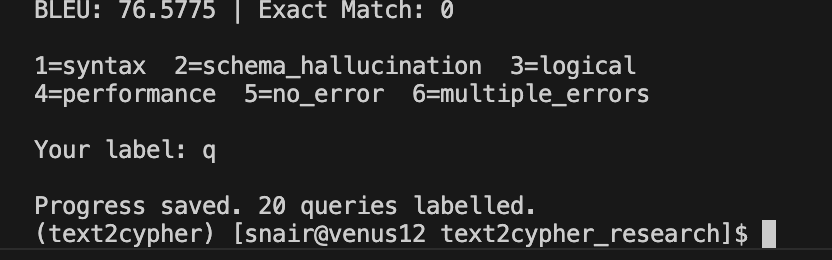

| Error Type | Count |
|---|---|
| No error | 13 |
| Logical error | 6 |
| Multiple errors | 1 |
| Syntax error | 0 |
| Schema hallucination | 0 |

---

### Interesting findings from today

**Finding 1 — No syntax errors in simple queries**
All 20 simple queries were syntactically valid. Gemini
can write correct Cypher grammar for basic queries.

**Finding 2 — Logical errors are most common**
6 out of 20 had logical errors. Common causes:
- Wrong relationship direction
- Property name case mismatch (Cylinders vs cylinders)
- Including punctuation in search strings (Solut! instead of Solut)
- Missing ORDER BY when question asks for first results

**Finding 3 — BLEU 100 with EM 0 confirmed again**
Query 19 had BLEU 100 but Exact Match 0 — identical query
just formatted differently across multiple lines. Confirms
BLEU cannot detect formatting differences and EM is too strict.
Strong evidence for RQ2.

**Finding 4 — Gemini sometimes improves on the reference**
Query 4 added DISTINCT which is arguably more correct.
Query 11 added a NULL check which handles missing data better.
Raises an interesting question about whether the reference
is always the true ground truth.

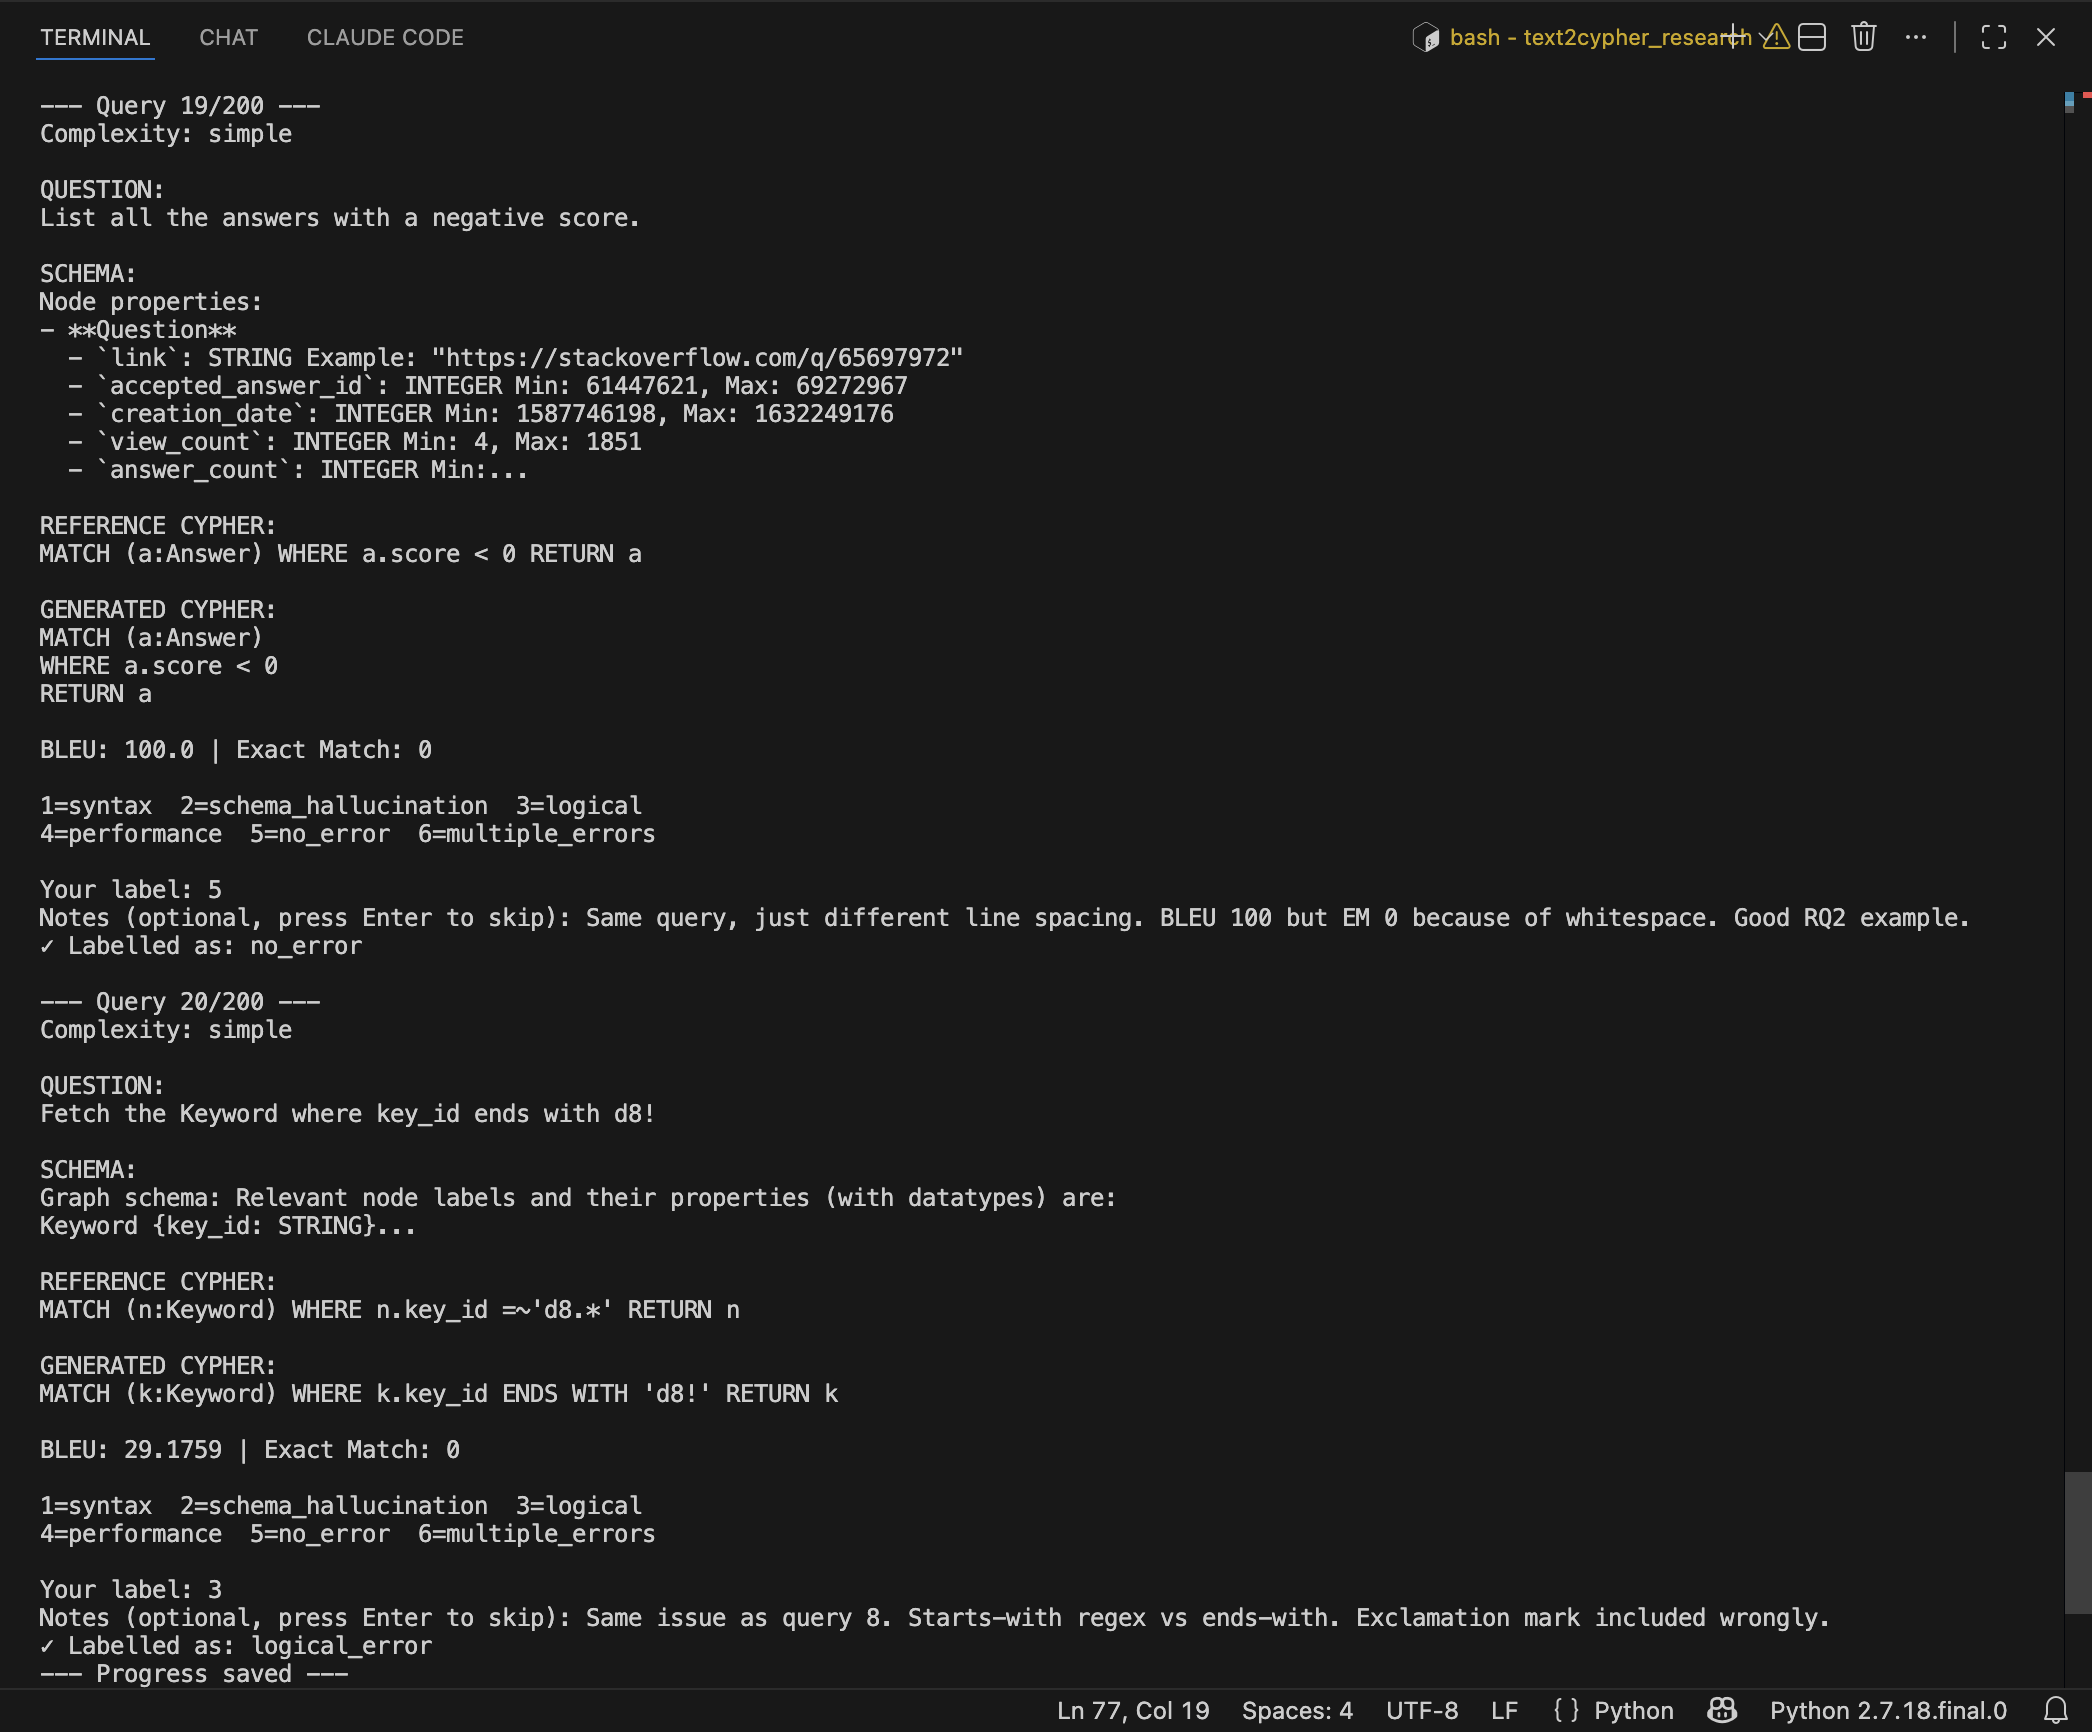

---

### Notable examples

**Query 2 — Relationship direction reversed**
Question asked for tweets with most replies.
Reference finds tweets that ARE replies.
Generated finds tweets that RECEIVE replies.
Direction flipped — completely different answer.

**Query 16 — Multiple errors**
Wrong property value 'Yes' vs 'Y' AND added a relationship
that may not exist in the schema. First multiple-error example.

**Query 8 and 20 — Same mistake pattern twice**
Both questions ended with ! as punctuation. Gemini included
! in the search string both times. Consistent mistake pattern.

---

### Files updated this session
| File | Update |
|---|---|
| data/generated_queries.csv | manual_label and label_notes columns added |
| scripts/label_queries.py | New interactive labelling script created |

---

### What I need to do next — July 11
- Label queries 21 to 35 (15 more)
- Expect schema hallucinations in medium complexity queries
- Target: 40 queries labelled by July 12

### Status vs timeline
- ✅ Phase 1 Setup: Complete
- ✅ Phase 2 Query Generation: Complete
- 🔄 Phase 3 Taxonomy Validation: 20/40 done
- ✅ On track

## Entry 7 — 15 July 2026
**Session duration:** 2 hours  
**Phase:** Phase 3 — Taxonomy Validation Complete  
**Goal:** Complete all 40 manual labels (achieved 41)

---

### What I did today

Completed manual labelling of 41 simple queries from
generated_queries.csv using scripts/label_queries.py.
Each query was read carefully, compared to the reference
Cypher, and assigned one of six labels.

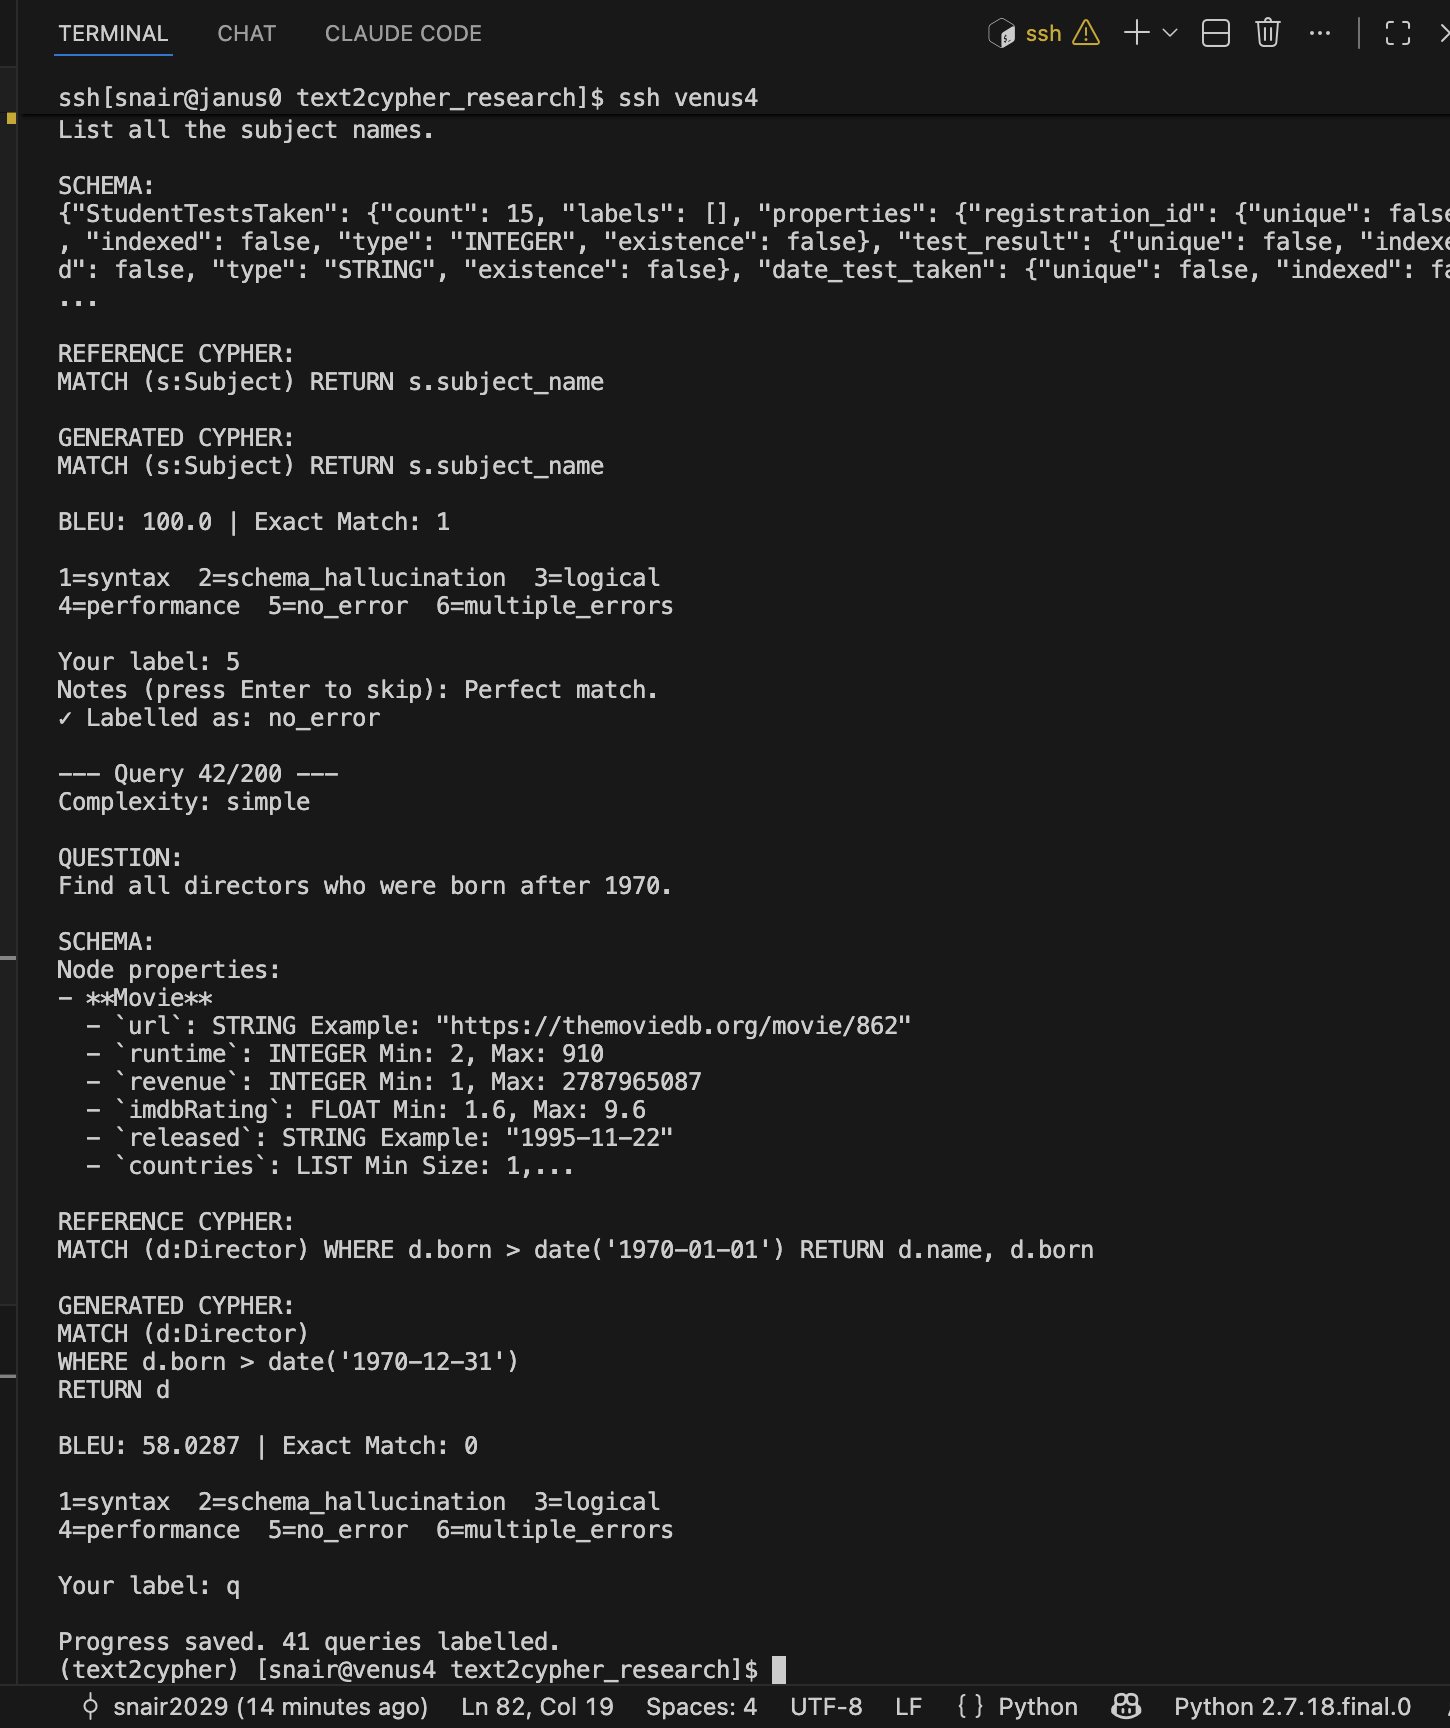

---

### Final label distribution — 41 simple queries

| Error Type | Count | Percentage |
|---|---|---|
| No error | 31 | 75.6% |
| Logical error | 8 | 19.5% |
| Multiple errors | 2 | 4.9% |
| Syntax error | 0 | 0% |
| Schema hallucination | 0 | 0% |

---

### Key findings from manual labelling

**Finding 1 — No syntax errors in simple queries**
Gemini 3.1 Flash Lite produced zero syntactically broken
queries across all 41 simple questions. It understands
basic Cypher grammar well for straightforward lookups.

**Finding 2 — Logical errors are the dominant failure mode**
8 out of 41 queries had logical errors. Most common causes:
- Wrong relationship direction
- Property name case mismatch
- Including punctuation in search strings
- Missing ORDER BY when question asks for ordered results
- Wrong property values ('Yes' vs 'Y', 'English' vs 'english')

**Finding 3 — Punctuation pattern observed**
Queries ending with ! (e.g. "Find Article where title
contains Solut!") caused Gemini to include the ! in
the search string. This happened consistently across
multiple queries — a repeatable error pattern.

**Finding 4 — BLEU 100 with EM 0 confirmed multiple times**
Several queries scored BLEU 100 but Exact Match 0 due to:
- Different formatting (whitespace, line breaks)
- Different variable names
- count(*) vs count(n)
- Single vs double quotes
All produce identical results but BLEU and EM treat them
differently. Strong ongoing evidence for RQ2.

**Finding 5 — Gemini sometimes improves on reference**
Multiple queries where generated output was arguably better:
- Added DISTINCT when question implies unique results
- Added NULL checks before sorting
- Returned specific fields instead of whole node
This raises an important question: is the reference query
always the ground truth? This will be discussed in the
final report.

**Finding 6 — Zero schema hallucinations in simple queries**
Gemini correctly used existing node labels and relationship
types for all simple queries. Schema hallucinations are
expected to appear in medium and complex queries where
the schema is more complex.

---

### What these findings mean for RQ1 and RQ2

**RQ1** — The most common failure mode in simple queries
is logical errors (19.5%). Syntax errors and schema
hallucinations were absent at this complexity level.
This suggests Gemini's failures are semantic rather
than syntactic for simple tasks.

**RQ2** — BLEU and Exact Match consistently fail to
distinguish between correct and incorrect queries.
Multiple no-error queries scored low BLEU due to
valid alternative syntax. Multiple identical queries
scored BLEU 100 with EM 0 due to formatting.
The metrics are clearly insufficient as sole evaluators.

---

### Files updated this session
| File | Update |
|---|---|
| data/generated_queries.csv | 41 queries labelled with manual_label and label_notes |
| scripts/label_queries.py | Fixed label detection bug |

---

### What I need to do next
- Phase 3 complete for simple queries
- Begin building the automated error classification pipeline
- Start with syntax classifier (Phase 4 — August)
- Pipeline will classify all 200 queries automatically
- Manual labels serve as validation ground truth

### Status vs timeline
- ✅ Phase 1 Setup: Complete
- ✅ Phase 2 Query Generation: Complete
- ✅ Phase 3 Taxonomy Validation: Complete (41 queries labelled)
- 🔄 Phase 4 Pipeline Build: Starting August
- ✅ On track